# Final investigation: hidden-layer ratios and winning tickets

## 1. Research overview

The **Lottery Ticket Hypothesis** proposes that a dense randomly initialized network contains sparse subnetworks which, with their original initialization, can train effectively. Our research question is:

**How does the ratio between hidden-layer widths affect the accuracy and trainability of winning tickets when the total parameter count is held approximately constant?**

Frankle and Carbin (2019), Appendix **G.6**, vary fully connected network size while retaining a **3:1** hidden-layer ratio. We investigate changing that allocation at approximately 200k dense parameters: first-layer narrow A, nearly balanced B, and 3:1 C. Our hypothesis is that allocation influences the validation accuracy and training iteration of sparse tickets; it does not presuppose a best ratio.

The historical stages established the implementation, pilots, three-seed main experiment, same-mask controls, and final validation-selected held-out evaluation. This notebook synthesizes that evidence through reusable tested Python functions rather than concatenating milestone notebooks.

**Default Mode A never trains or reevaluates held-out data.** It verifies and loads frozen measurements, reproduces aggregate tables, and regenerates `paper_assets/`. Mode B is a separate explicitly enabled full reproduction with new output directories.

## 2. Experimental configuration

MNIST **55,000 training / 5,000 validation / 10,000 test**, split seed **42**. Model seeds **0,1,2**. Adam, learning rate **0.0012**, batch size **60**, Gaussian Glorot initialization and ReLU hidden layers. Each IMP stage trained **10,000 fixed updates**, validating every **100**. Twelve pruning rounds plus dense baseline. Each round removes floor(20% of surviving hidden-layer weights) and floor(10% of surviving output weights), independently per layer. Biases stay dense. Surviving weights and biases rewind to original initialization; Adam is fresh each stage.

Selection is retrospective minimum validation loss (earlier point retained for exact ties); future masks come from the **final 10k state**, not selected weights. The original paper used 50k updates. Our primary model counts are approximate, not exactly equal.

In [1]:
# Change BOTH settings only to intentionally launch the full new reproduction.
MODE = "A"
ENABLE_FULL_REPRODUCTION = False
REPRODUCTION_OUTPUT = "reproductions/full_run"

import os,tempfile,json,inspect
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR",str(Path(tempfile.gettempdir())/"lottery-final-mpl"))
import pandas as pd
import torch
import yaml
from IPython.display import display,Image,Markdown
from final_project import ROOT,LABELS,verify_artifacts,generate_assets
from models import MLP,ARCHITECTURES,parameter_count
from data import set_seed
from pruning import make_masks,prune_masks,rewind_weights,apply_masks
from train import train_stage,evaluate
if MODE not in ("A","B"): raise ValueError("Choose Mode A or B explicitly")
if MODE=="A" and ENABLE_FULL_REPRODUCTION: raise ValueError("Mode A cannot enable training")
config=yaml.safe_load((ROOT/"config_final.yaml").read_text())
display(config)
counts=pd.DataFrame([dict(architecture=LABELS[a],hidden1=ARCHITECTURES[a][0],hidden2=ARCHITECTURES[a][1],parameters=parameter_count(MLP(*ARCHITECTURES[a]))) for a in LABELS])
assert counts.parameters.tolist()==[200013,200054,199979]
display(counts)

{'architectures': {'A': [162, 421], 'B': [200, 204], 'C': [231, 77]},
 'model_seeds': [0, 1, 2],
 'split_seed': 42,
 'iterations': 10000,
 'eval_interval': 100,
 'rounds': 12,
 'learning_rate': 0.0012,
 'batch_size': 60,
 'hidden_pruning_rate': 0.2,
 'output_pruning_rate': 0.1,
 'initialization': 'gaussian_glorot',
 'optimizer': 'Adam',
 'control_stages': [6, 12],
 'test_stages': [0, 6, 12],
 'device': 'cpu',
 'num_threads': 1,
 'data_dir': 'datasets'}

,architecture,hidden1,hidden2,parameters
0,A (162–421),162,421,200013
1,B (200–204),200,204,200054
2,C (231–77),231,77,199979


## 3. Model and pruning implementation

`models.MLP` implements 784 → hidden1 → hidden2 → 10, Xavier/Gaussian Glorot weights (gain 1), zero biases and ReLU hidden layers. `prune_masks` ranks magnitudes among current survivors independently by layer; stable index ordering resolves ties. Masks are boolean and previously pruned positions cannot return. `rewind_weights` reloads the original state, including biases, then enforces the mask.

The following is a small **untrained implementation demonstration**, not an experiment or source of scientific measurements. The actual experiments pruned fully trained final states. `train_stage` constructs fresh Adam, masks gradients and reapplies masks after every update; `evaluate` returns example-weighted cross-entropy and accuracy. We import these implementations without executing training here.

In [2]:
set_seed(0)
demo=MLP(4,3)
initial={k:v.detach().clone() for k,v in demo.state_dict().items()}
original_masks=make_masks(demo)
pruned=prune_masks(demo,original_masks,hidden_rate=0.2,output_rate=0.1)
rewind_weights(demo,initial,pruned)
for name,mask in pruned.items():
    assert torch.equal(getattr(demo,name).weight.detach()[mask],initial[name+".weight"][mask])
    assert getattr(demo,name).weight.detach()[~mask].count_nonzero()==0
    assert torch.all(mask <= original_masks[name])
print("Demonstration passed: survivor restoration, mask monotonicity, pruned zeros.")
print("Training API:",inspect.signature(train_stage))
print("Evaluation API:",inspect.signature(evaluate))

Demonstration passed: survivor restoration, mask monotonicity, pruned zeros.
Training API: (model: 'nn.Module', train_loader, val_loader, masks: 'dict[str, torch.Tensor]', *, iterations: 'int' = 10000, learning_rate: 'float' = 0.0012, eval_interval: 'int' = 500, device: 'str | torch.device' = 'cpu', progress: 'bool' = True, trace_interval: 'int | None' = None, history_callback=None) -> 'dict'
Evaluation API: (model: 'nn.Module', loader, device: 'str | torch.device' = 'cpu') -> 'dict[str, float]'


## 4. Main three-seed experiment

Mode A reads the approved **117 observed architecture–seed–stage measurements**. The analysis recomputes means and **sample standard deviations**, checking the stored approved tables to absolute tolerance 1e-10 (CSV rounding). Thin lines show individual seeds. Remaining parameters count active mask positions plus biases; equal pruning rounds do not imply equal parameter counts.

The earlier common-budget 16k/20k comparisons are **interpolated validation estimates**, not observed checkpoints. The plots below use observed stages only. Mode B requires the separate boolean opt-in and uses the same frozen methodology, writes only under `reproductions/NAME`, captures best states during training, and is resumable at completed-stage boundaries. It is not launched by default.

{'selected_checkpoints': 45, 'manifest_files_checked': 11, 'status': 'verified', 'training_performed': False}
{'output': 'paper_assets', 'figures': 11, 'tables': 14, 'training_performed': False, 'approved_aggregates_reproduced': True}


,architecture,stage,best_validation_accuracy_mean,best_validation_accuracy_std,best_validation_accuracy_min,best_validation_accuracy_max,best_validation_loss_mean,best_validation_loss_std,best_validation_loss_min,best_validation_loss_max,best_iteration_mean,best_iteration_std,best_iteration_min,best_iteration_max,accuracy_change_pp_mean,accuracy_change_pp_std,accuracy_change_pp_min,accuracy_change_pp_max,accuracy_degradation_pp_mean,accuracy_degradation_pp_std,accuracy_degradation_pp_min,accuracy_degradation_pp_max,training_loss_mean,training_loss_std,training_loss_min,training_loss_max,final_validation_loss_mean,final_validation_loss_std,final_validation_loss_min,final_validation_loss_max,final_validation_accuracy_mean,final_validation_accuracy_std,final_validation_accuracy_min,final_validation_accuracy_max,runtime_seconds_mean,runtime_seconds_std,runtime_seconds_min,runtime_seconds_max,remaining_parameters,remaining_weights,remaining_percent,sparsity,parameters,seed_count,late_minima_count,budget_concerns_count
0,A,0,0.979333,0.000808,0.9786,0.9802,0.077330,0.001474,0.075865,0.078812,4300.000000,1637.070554,2500,5700,0.000000e+00,0.000000,-0.00,-0.00,0.000000e+00,0.000000,0.00,0.00,0.056314,0.000543,0.055965,0.056940,0.108745,0.009897,0.097528,0.116246,0.976333,0.001604,0.9748,0.9780,52.739682,10.225879,40.985606,59.591335,200013,199420,100.000000,0.000000,200013,3,0,0
1,A,1,0.977733,0.001501,0.9762,0.9792,0.075371,0.004156,0.071534,0.079786,3400.000000,964.365076,2300,4100,-1.600000e-01,0.138564,-0.24,-0.00,1.600000e-01,0.138564,0.00,0.24,0.046382,0.000571,0.045752,0.046864,0.117946,0.013655,0.104428,0.131733,0.976200,0.001400,0.9752,0.9778,68.933240,12.255806,54.960643,77.863677,160551,159958,80.211614,0.197884,200013,3,0,0
2,A,2,0.979000,0.003000,0.9760,0.9820,0.073288,0.004608,0.068542,0.077744,2400.000000,529.150262,1800,2800,-3.333333e-02,0.380175,-0.42,0.34,3.333333e-02,0.380175,-0.34,0.42,0.037039,0.000528,0.036439,0.037434,0.115628,0.014576,0.103498,0.131797,0.977267,0.001815,0.9756,0.9792,70.250505,13.084709,62.571272,85.358735,128940,128347,64.360144,0.356399,200013,3,0,0
3,A,3,0.978267,0.002663,0.9760,0.9812,0.069980,0.003530,0.066968,0.073864,2066.666667,472.581563,1700,2600,-1.066667e-01,0.318957,-0.32,0.26,1.066667e-01,0.318957,-0.26,0.32,0.030206,0.000071,0.030162,0.030288,0.112182,0.011728,0.100095,0.123515,0.979867,0.001943,0.9782,0.9820,87.995862,17.590239,70.062584,105.221718,103612,103019,51.659312,0.483407,200013,3,0,0
4,A,4,0.979867,0.001026,0.9790,0.9810,0.065736,0.001960,0.063476,0.066966,2200.000000,360.555128,1800,2500,5.333333e-02,0.155349,-0.12,0.18,-5.333333e-02,0.155349,-0.18,0.12,0.025620,0.000279,0.025452,0.025943,0.125116,0.004291,0.120163,0.127704,0.977933,0.001102,0.9772,0.9792,85.169905,17.672657,65.808108,100.433222,83316,82723,41.481797,0.585182,200013,3,0,0
5,A,5,0.980667,0.001137,0.9794,0.9816,0.065813,0.002207,0.063564,0.067975,2166.666667,230.940108,1900,2300,1.333333e-01,0.194251,-0.08,0.30,-1.333333e-01,0.194251,-0.30,0.08,0.022795,0.000157,0.022627,0.022939,0.134027,0.030610,0.115430,0.169356,0.977067,0.004709,0.9722,0.9816,86.734959,20.380032,66.234356,106.992242,67049,66456,33.324641,0.666754,200013,3,0,0
6,A,6,0.980000,0.001114,0.9788,0.9810,0.065839,0.000401,0.065540,0.066295,2266.666667,351.188458,1900,2600,6.666667e-02,0.192180,-0.14,0.24,-6.666667e-02,0.192180,-0.24,0.14,0.021353,0.000225,0.021093,0.021496,0.139034,0.020260,0.115647,0.151255,0.976933,0.003535,0.9746,0.9810,74.210093,25.050772,58.744818,103.112523,54008,53415,26.785177,0.732148,200013,3,0,0
7,A,7,0.981067,0.001332,0.9796,0.9822,0.065384,0.000655,0.064799,0.066091,2033.333333,230.940108,1900,2300,1.733333e-01,0.202320,-0.06,0.30,-1.733333e-01,0.202320,-0.30,0.06,0.020774,0.000264,0.020471,0.020952,0.110391,0.001807,0.109277,0.112475,0.980867,0.000902,0.9800,0.9818,69.277500,3.956425,64.747303,72.053763,43550,42957,21.540969,0.784590,200013,3,0,0
8,A,8,0.981600,0.001058,0.9804,0.9824,0.064311,0.000982,0.06320

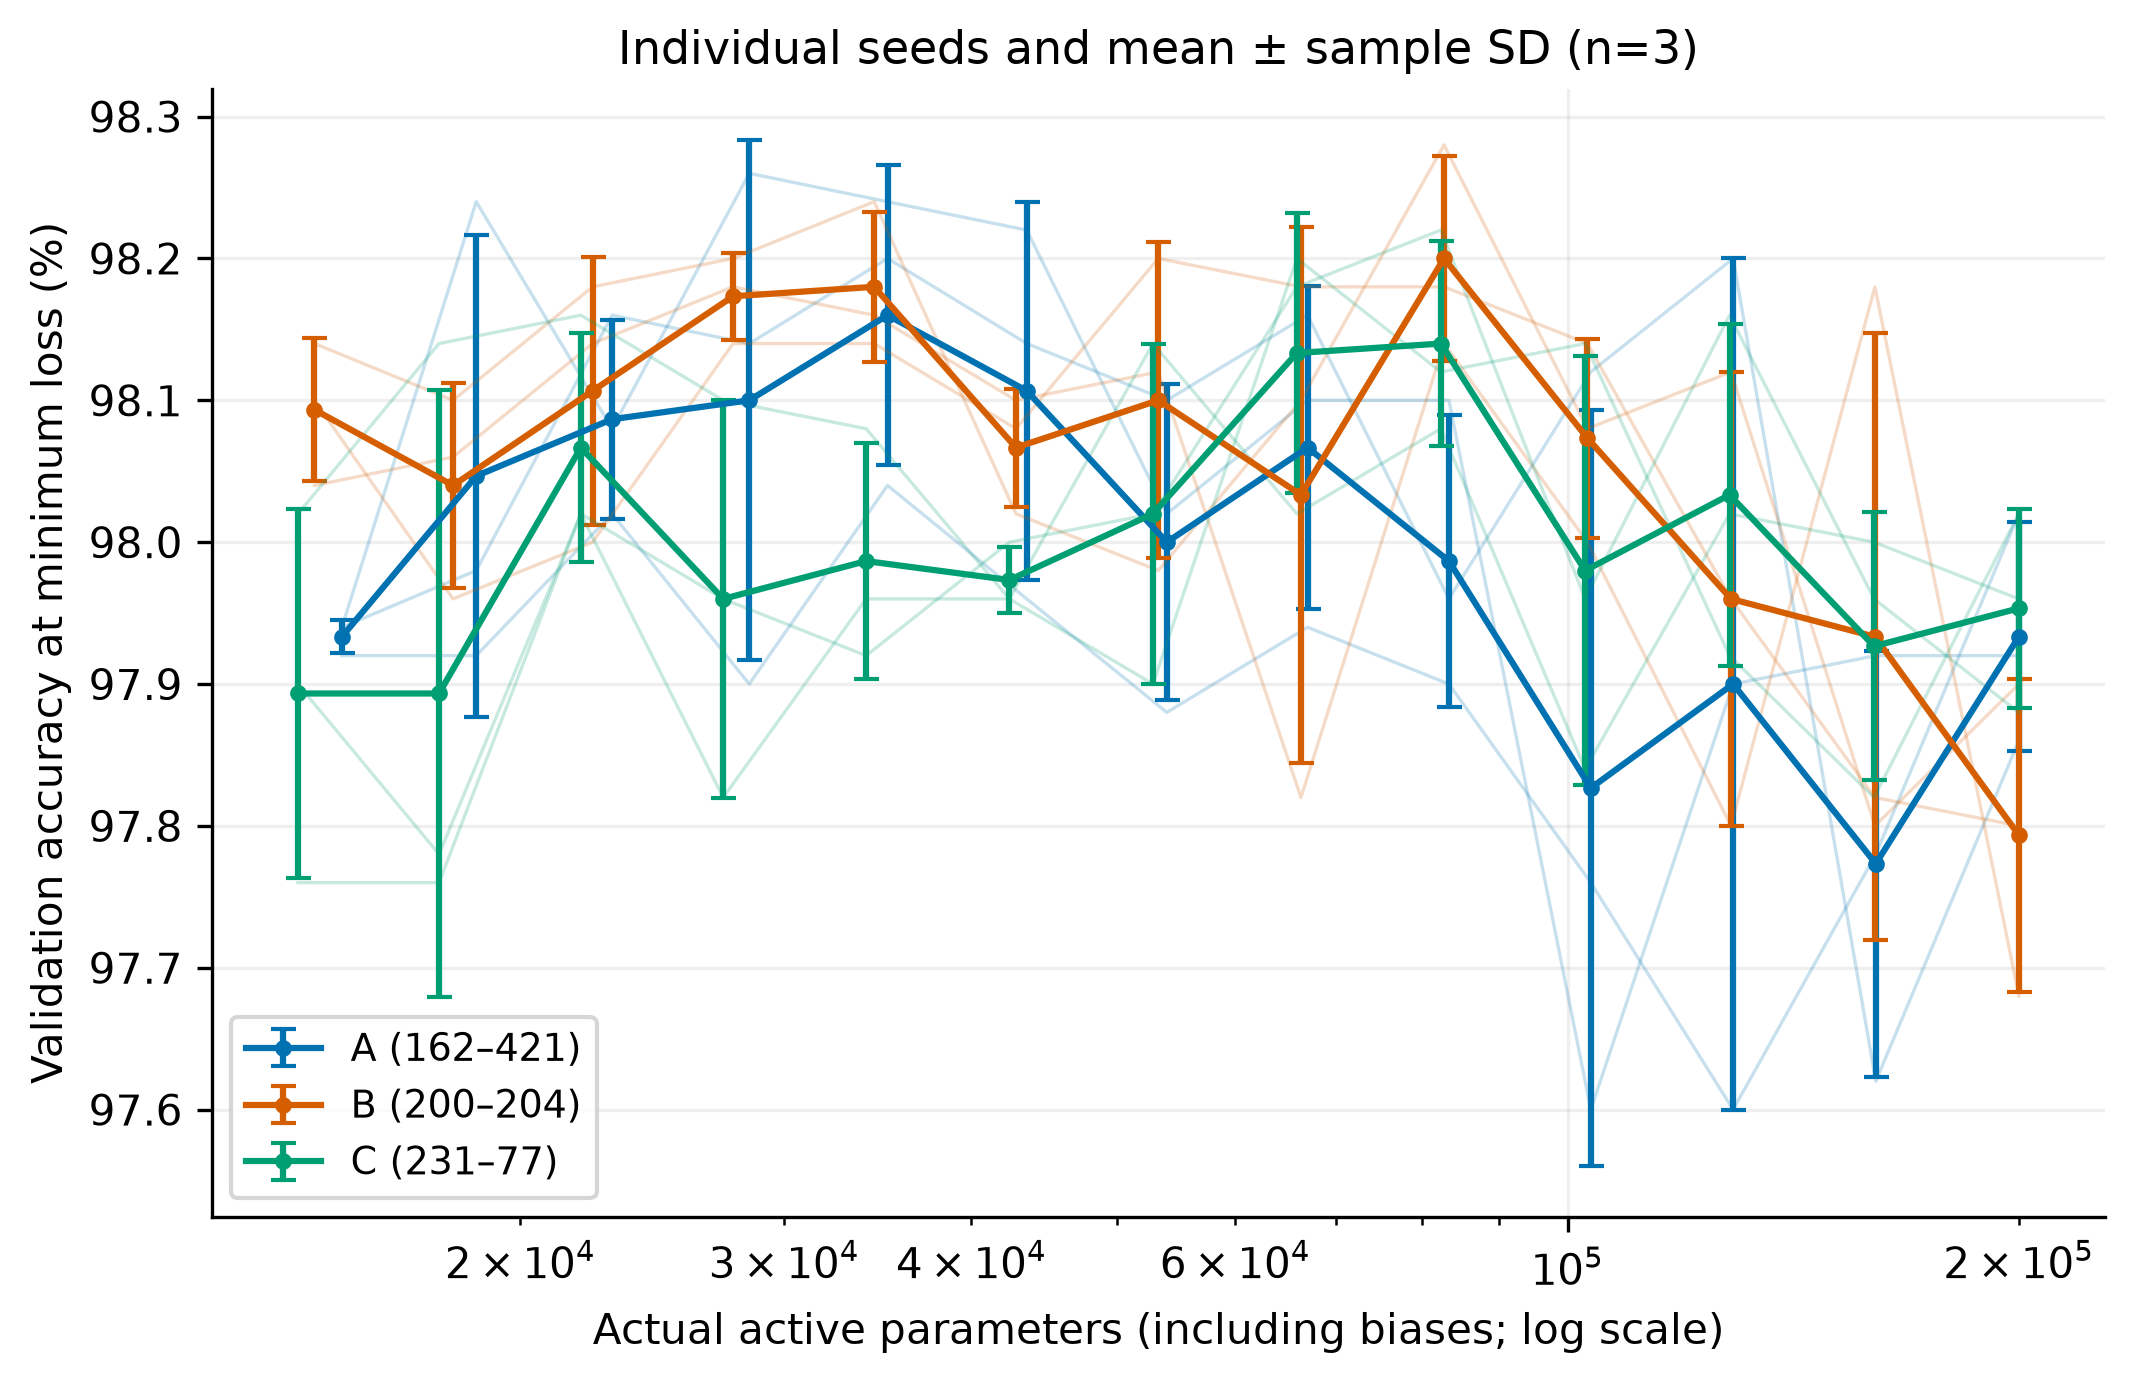

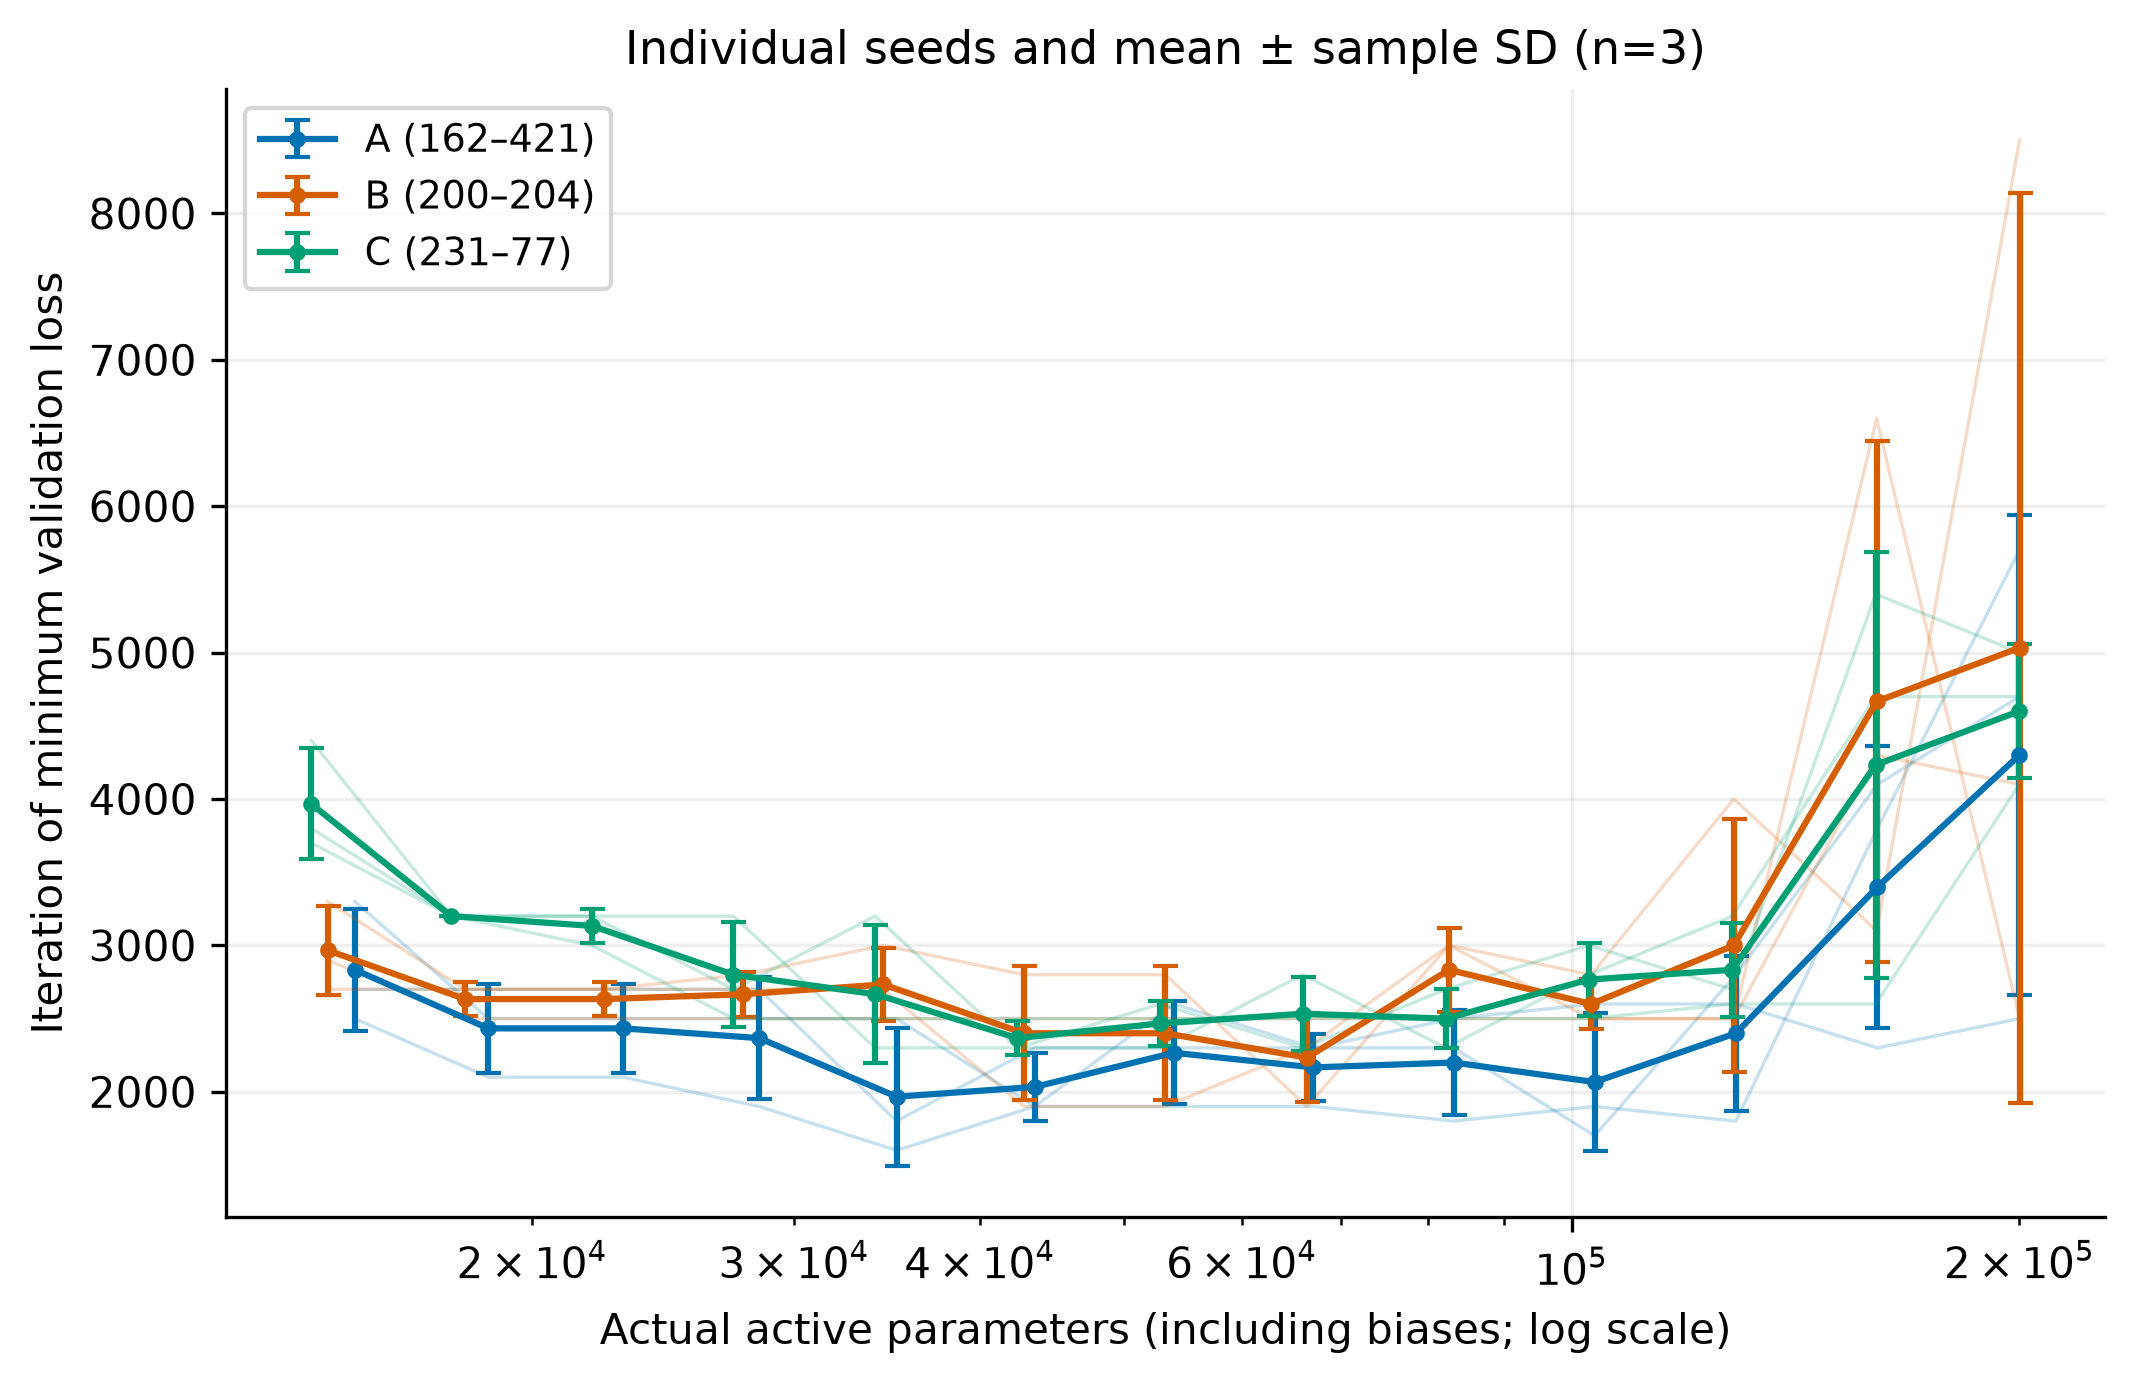

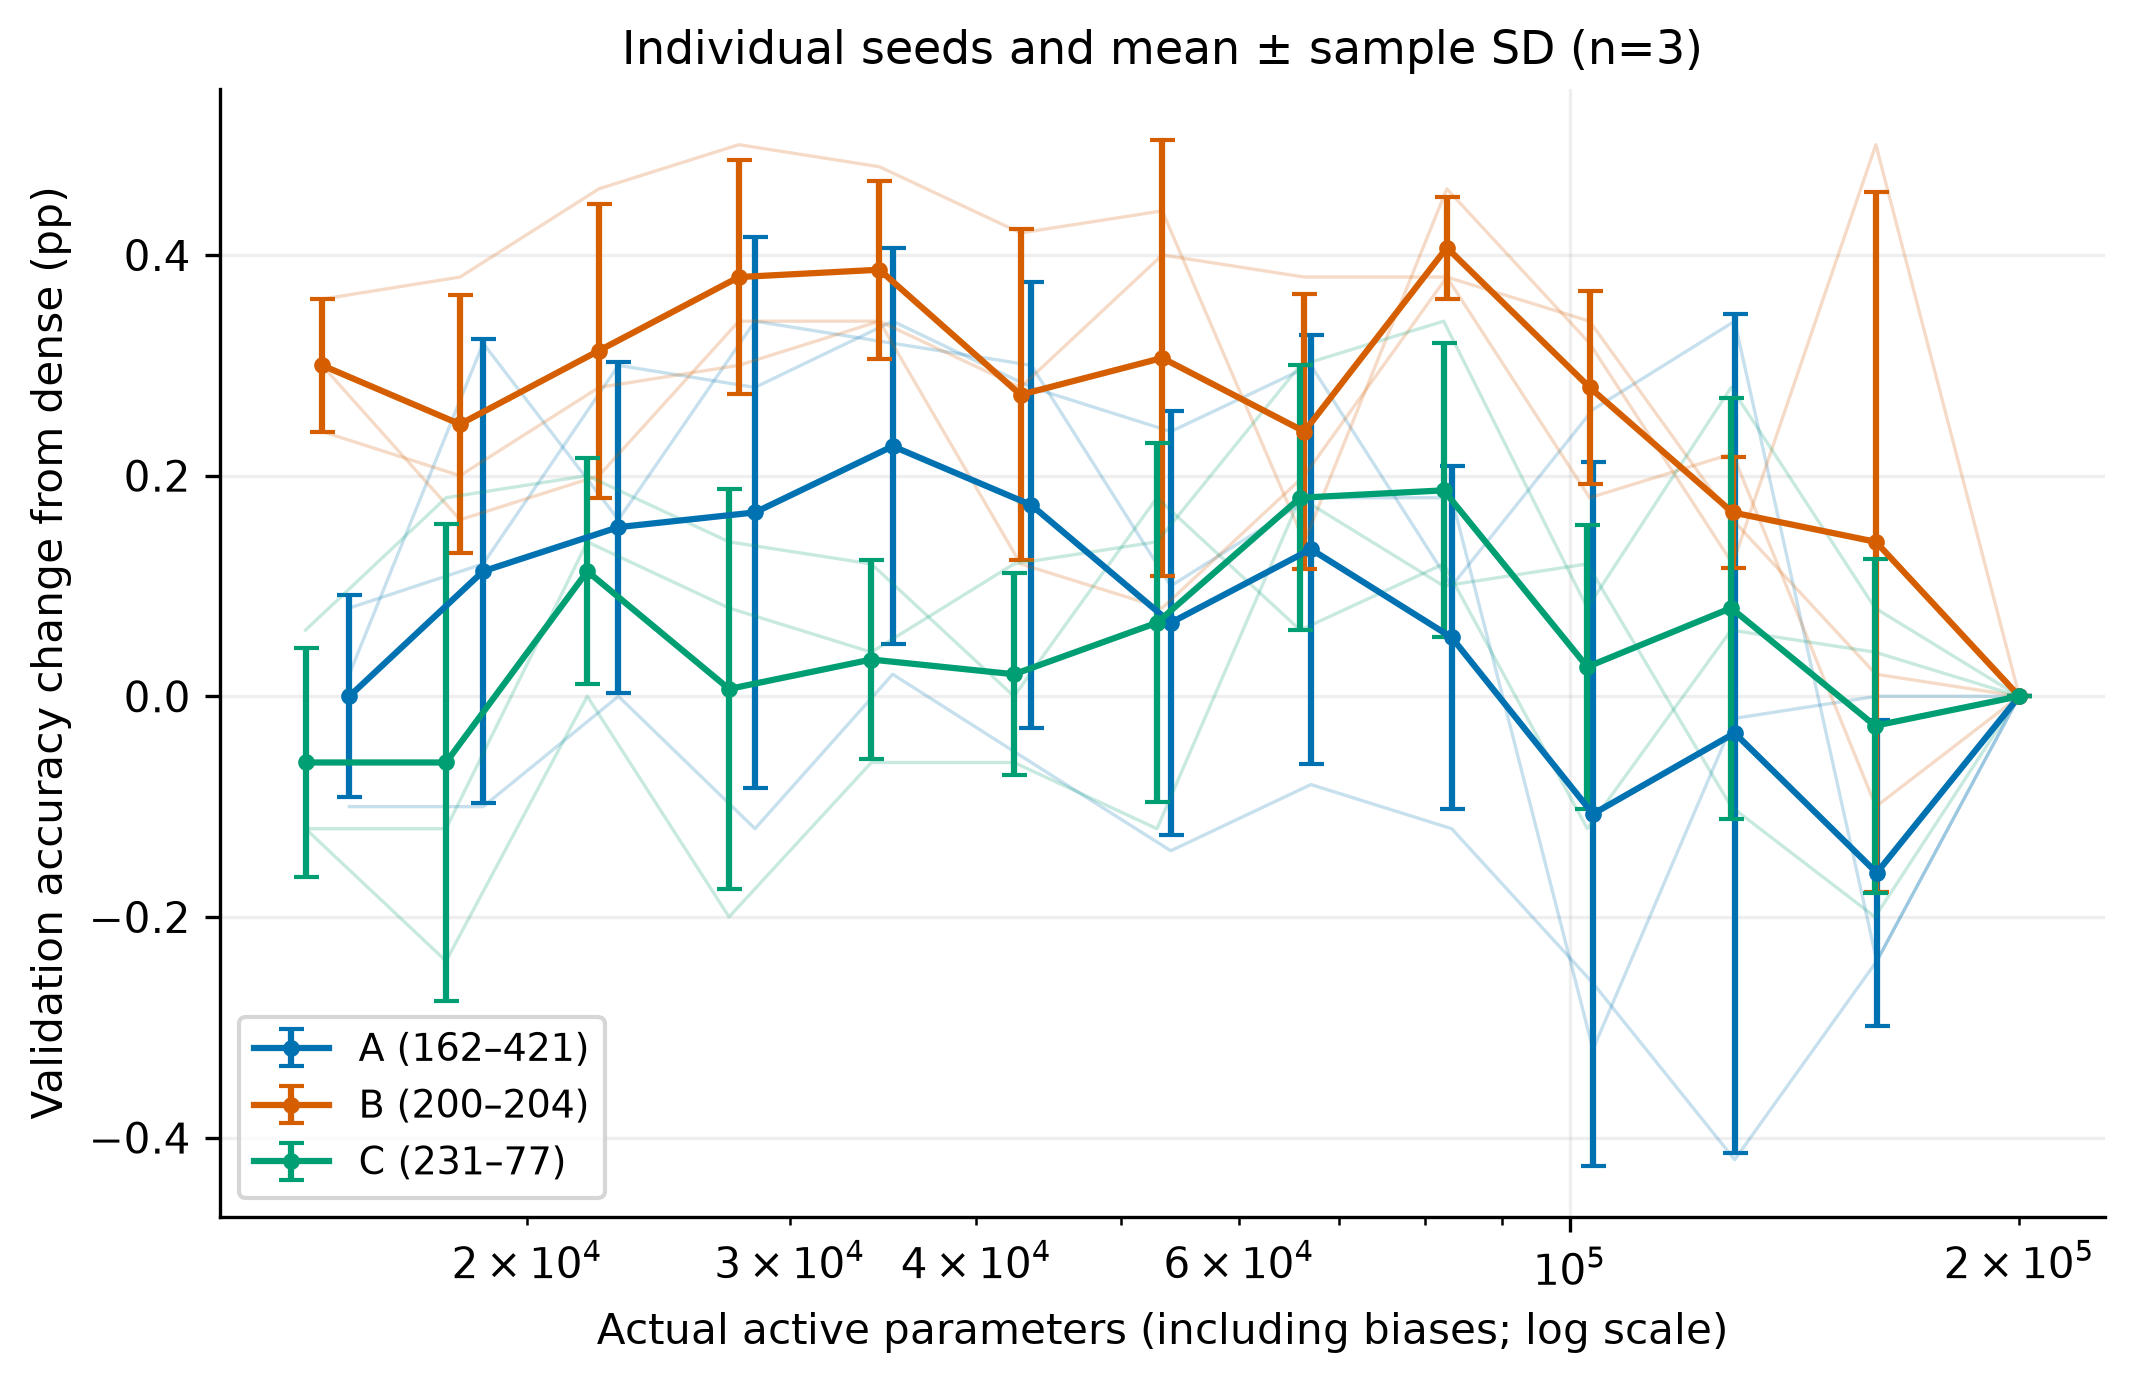

In [3]:
DATA_ROOT=ROOT
if MODE=="B":
    if ENABLE_FULL_REPRODUCTION is not True:
        raise PermissionError("Mode B requires explicit ENABLE_FULL_REPRODUCTION=True")
    from reproduce_final import full_reproduction
    DATA_ROOT=full_reproduction(REPRODUCTION_OUTPUT,enabled=True,workers=1)
    print("Analyzing NEW reproduction only:",DATA_ROOT.relative_to(ROOT))
else:
    print(verify_artifacts(DATA_ROOT))
results,asset_report=generate_assets(DATA_ROOT,output="paper_assets")
print(asset_report)
display(results["main_summary"])
for name in ("validation_accuracy_vs_parameters","minimum_loss_iteration_vs_parameters","dense_relative_validation_accuracy"):
    display(Image(filename=str(DATA_ROOT/"paper_assets"/f"{name}.png")))

## 5. Same-mask random-reinitialization controls

There are **18 controls**: A/B/C × seeds 0/1/2 × stages 6/12. Each uses exactly its ticket's active positions and batch order, but fresh Gaussian Glorot weights and fresh Adam. The independent predetermined initialization seed is `(seed + 1000003 + stage*1009) % 2**32`. Controls never affect subsequent IMP masks.

Accuracy is taken at the iteration of minimum validation loss. Differences are **ticket minus control**, paired within architecture, model seed and stage before computing mean/sample SD. Positive accuracy differences favor original initialization. Validation selection, loss and iteration are separate metrics.

,architecture,stage,ticket_minus_control_accuracy_pp_mean,ticket_minus_control_accuracy_pp_std,ticket_minus_control_accuracy_pp_min,ticket_minus_control_accuracy_pp_max,ticket_minus_control_loss_mean,ticket_minus_control_loss_std,ticket_minus_control_loss_min,ticket_minus_control_loss_max,ticket_minus_control_iteration_mean,ticket_minus_control_iteration_std,ticket_minus_control_iteration_min,ticket_minus_control_iteration_max,seed_count,ticket_accuracy_higher_count,control_accuracy_higher_count,accuracy_tied_count,remaining_parameters
0,A,6,0.093333,0.136137,-0.06,0.20,-0.010245,0.005265,-0.013954,-0.004219,-4800.000000,2042.057786,-6400,-2500,3,2,1,0,54008
1,A,12,0.600000,0.227156,0.34,0.76,-0.018558,0.002224,-0.020829,-0.016385,-6566.666667,763.762616,-7400,-5900,3,3,0,0,15203
2,B,6,0.233333,0.332466,-0.12,0.54,-0.017678,0.004932,-0.020599,-0.011984,-5700.000000,818.535277,-6600,-5000,3,2,1,0,53301
3,B,12,0.766667,0.223010,0.60,1.02,-0.028511,0.003094,-0.031989,-0.026064,-6333.333333,1159.022577,-7100,-5000,3,3,0,0,14575
4,C,6,0.280000,0.131149,0.14,0.40,-0.015887,0.006212,-0.020515,-0.008827,-5766.666667,208.166600,-6000,-5600,3,3,0,0,52870
5,C,12,1.106667,0.133167,1.02,1.26,-0.034298,0.006574,-0.039881,-0.027052,-5300.000000,721.110255,-6100,-4700,3,3,0,0,14209


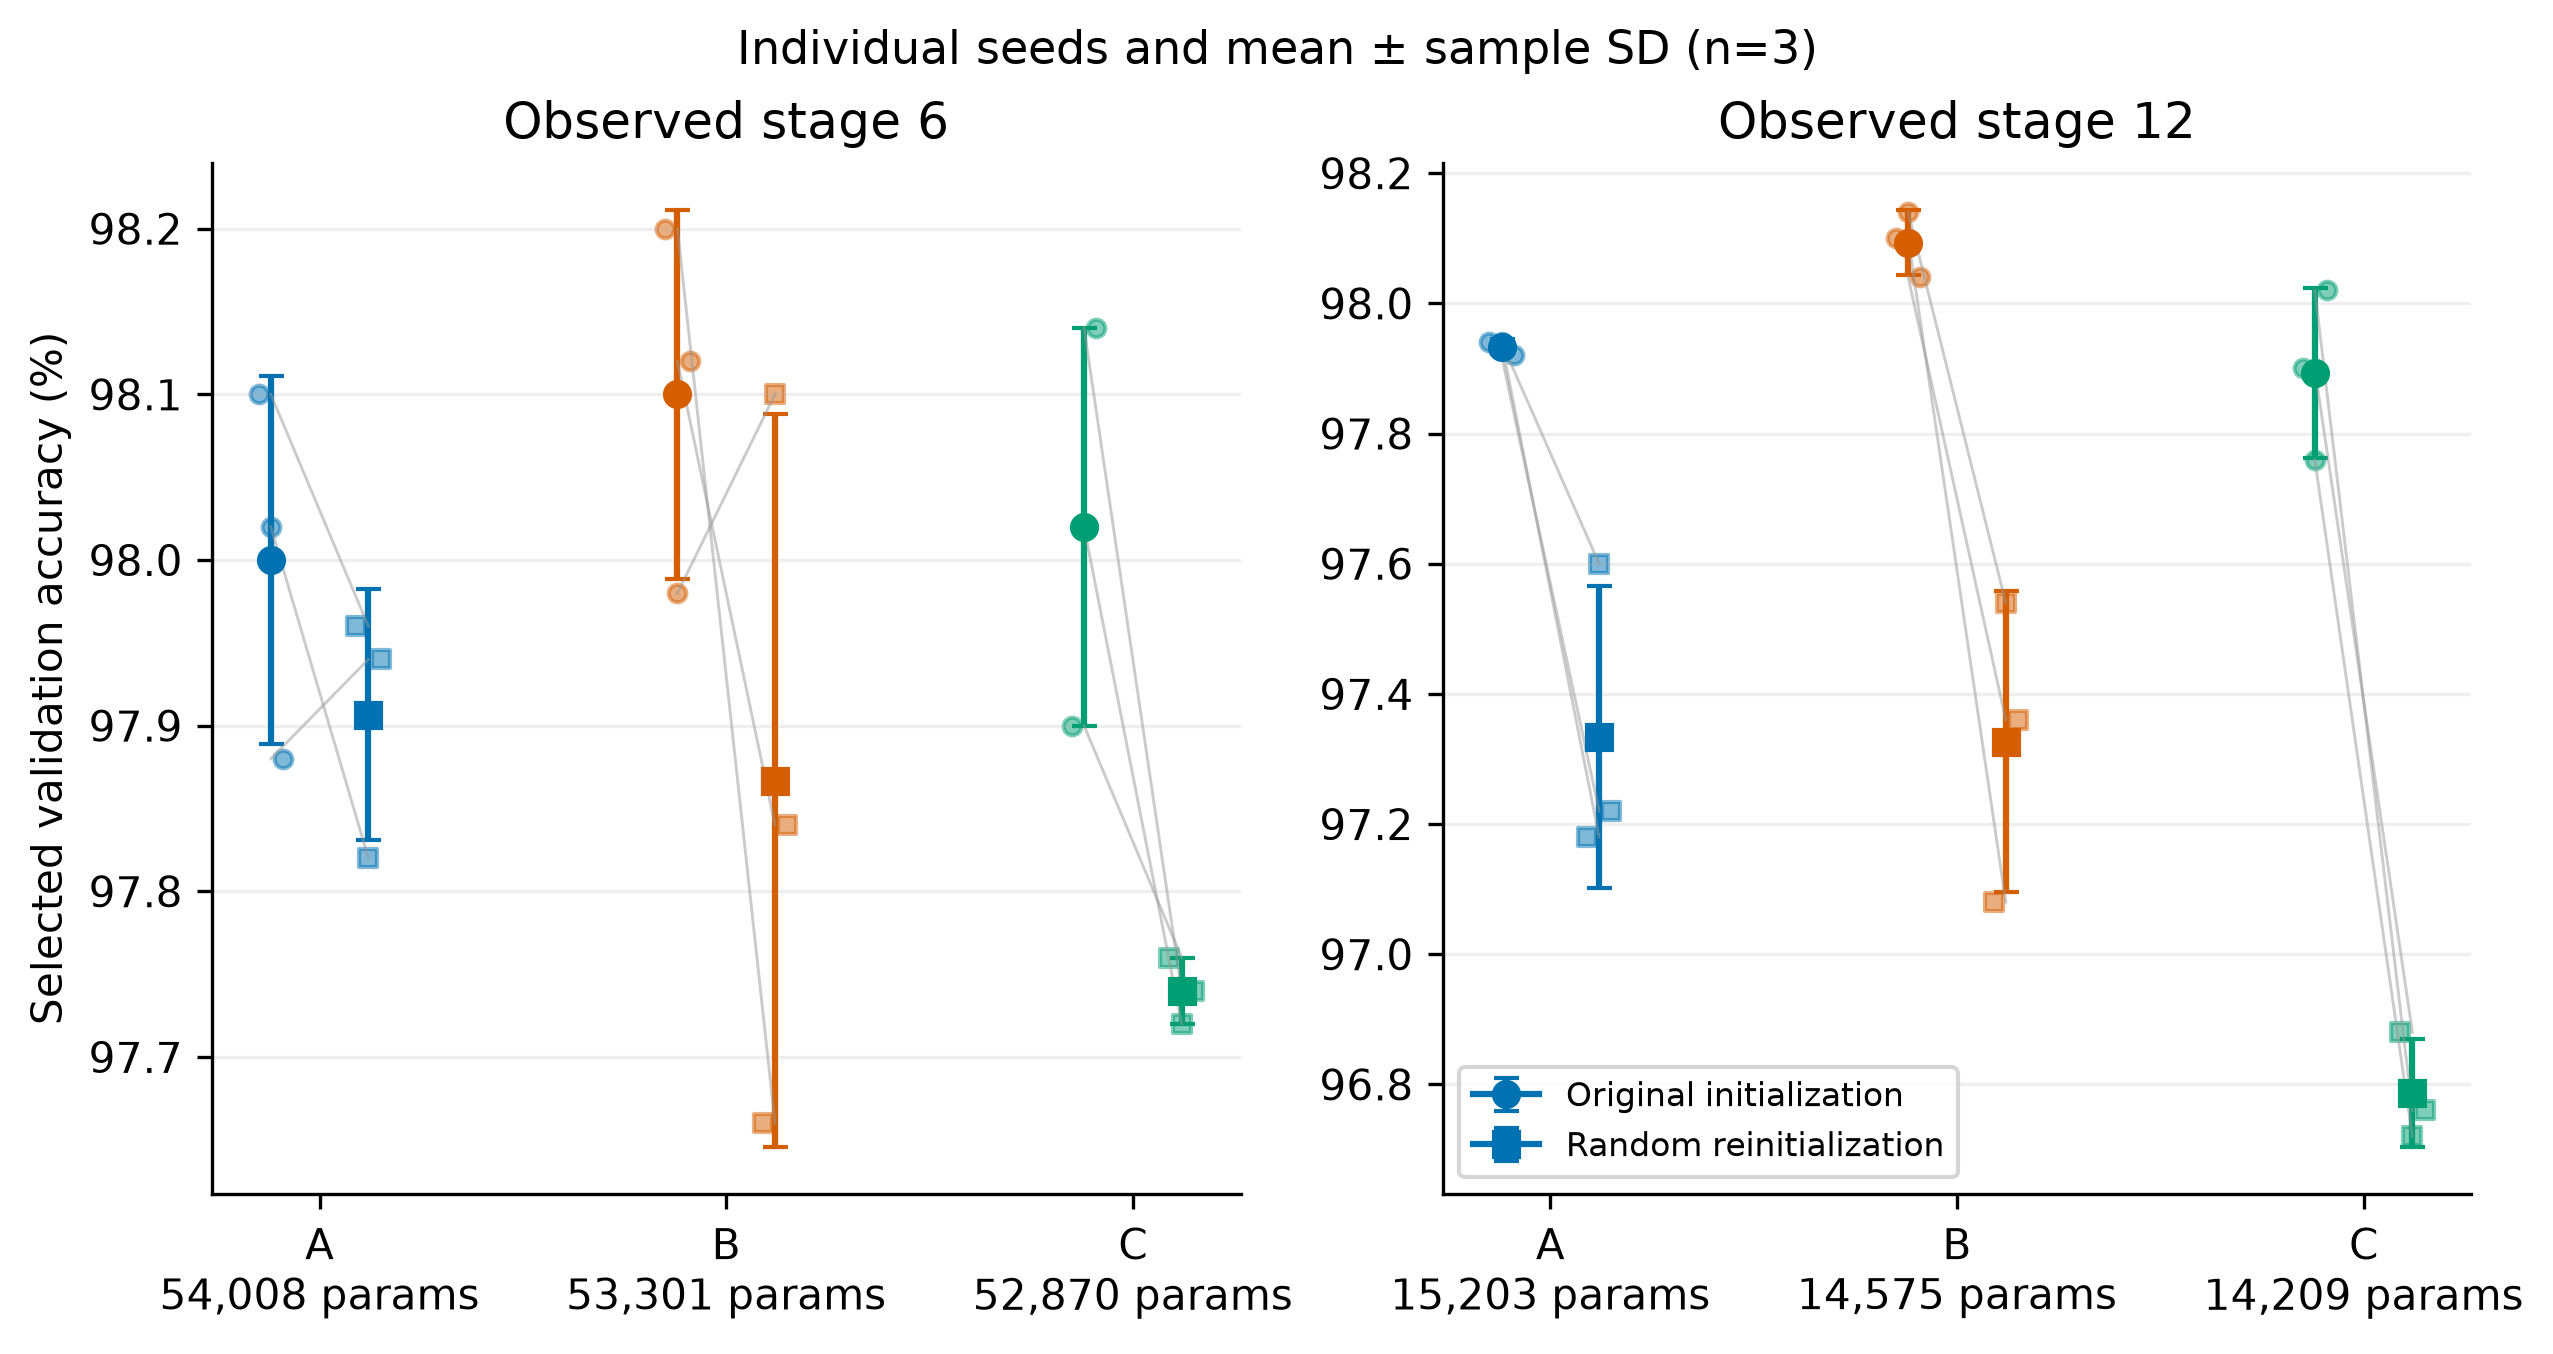

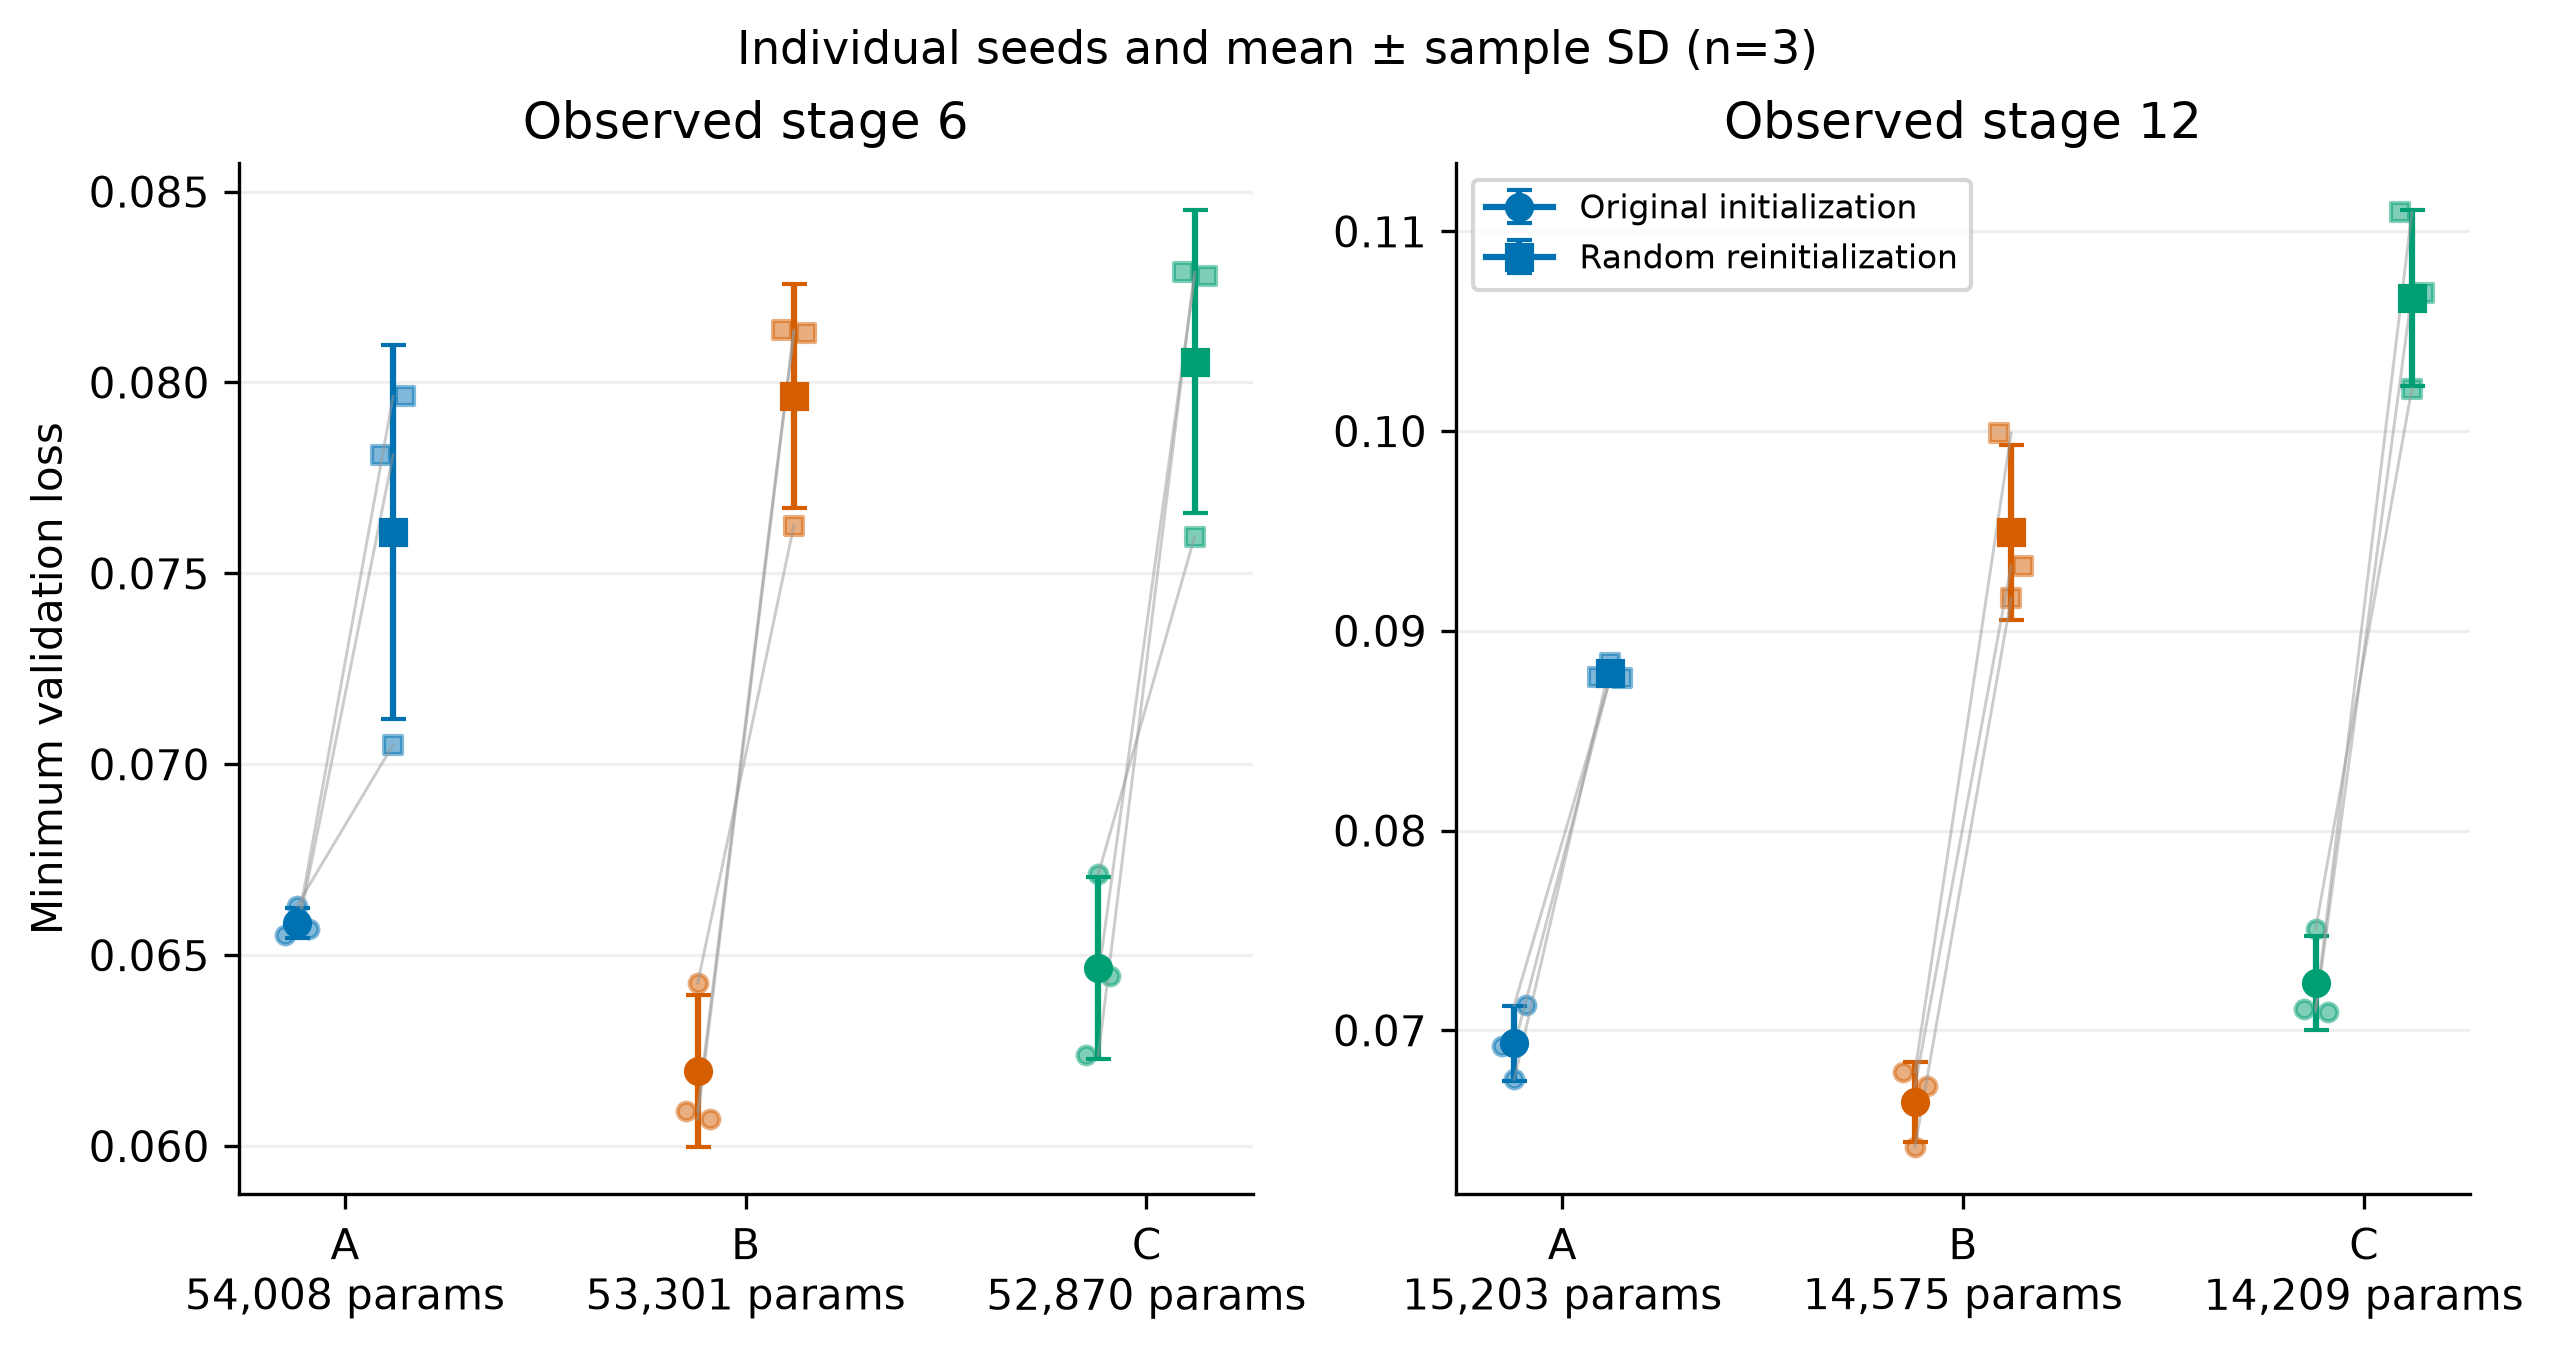

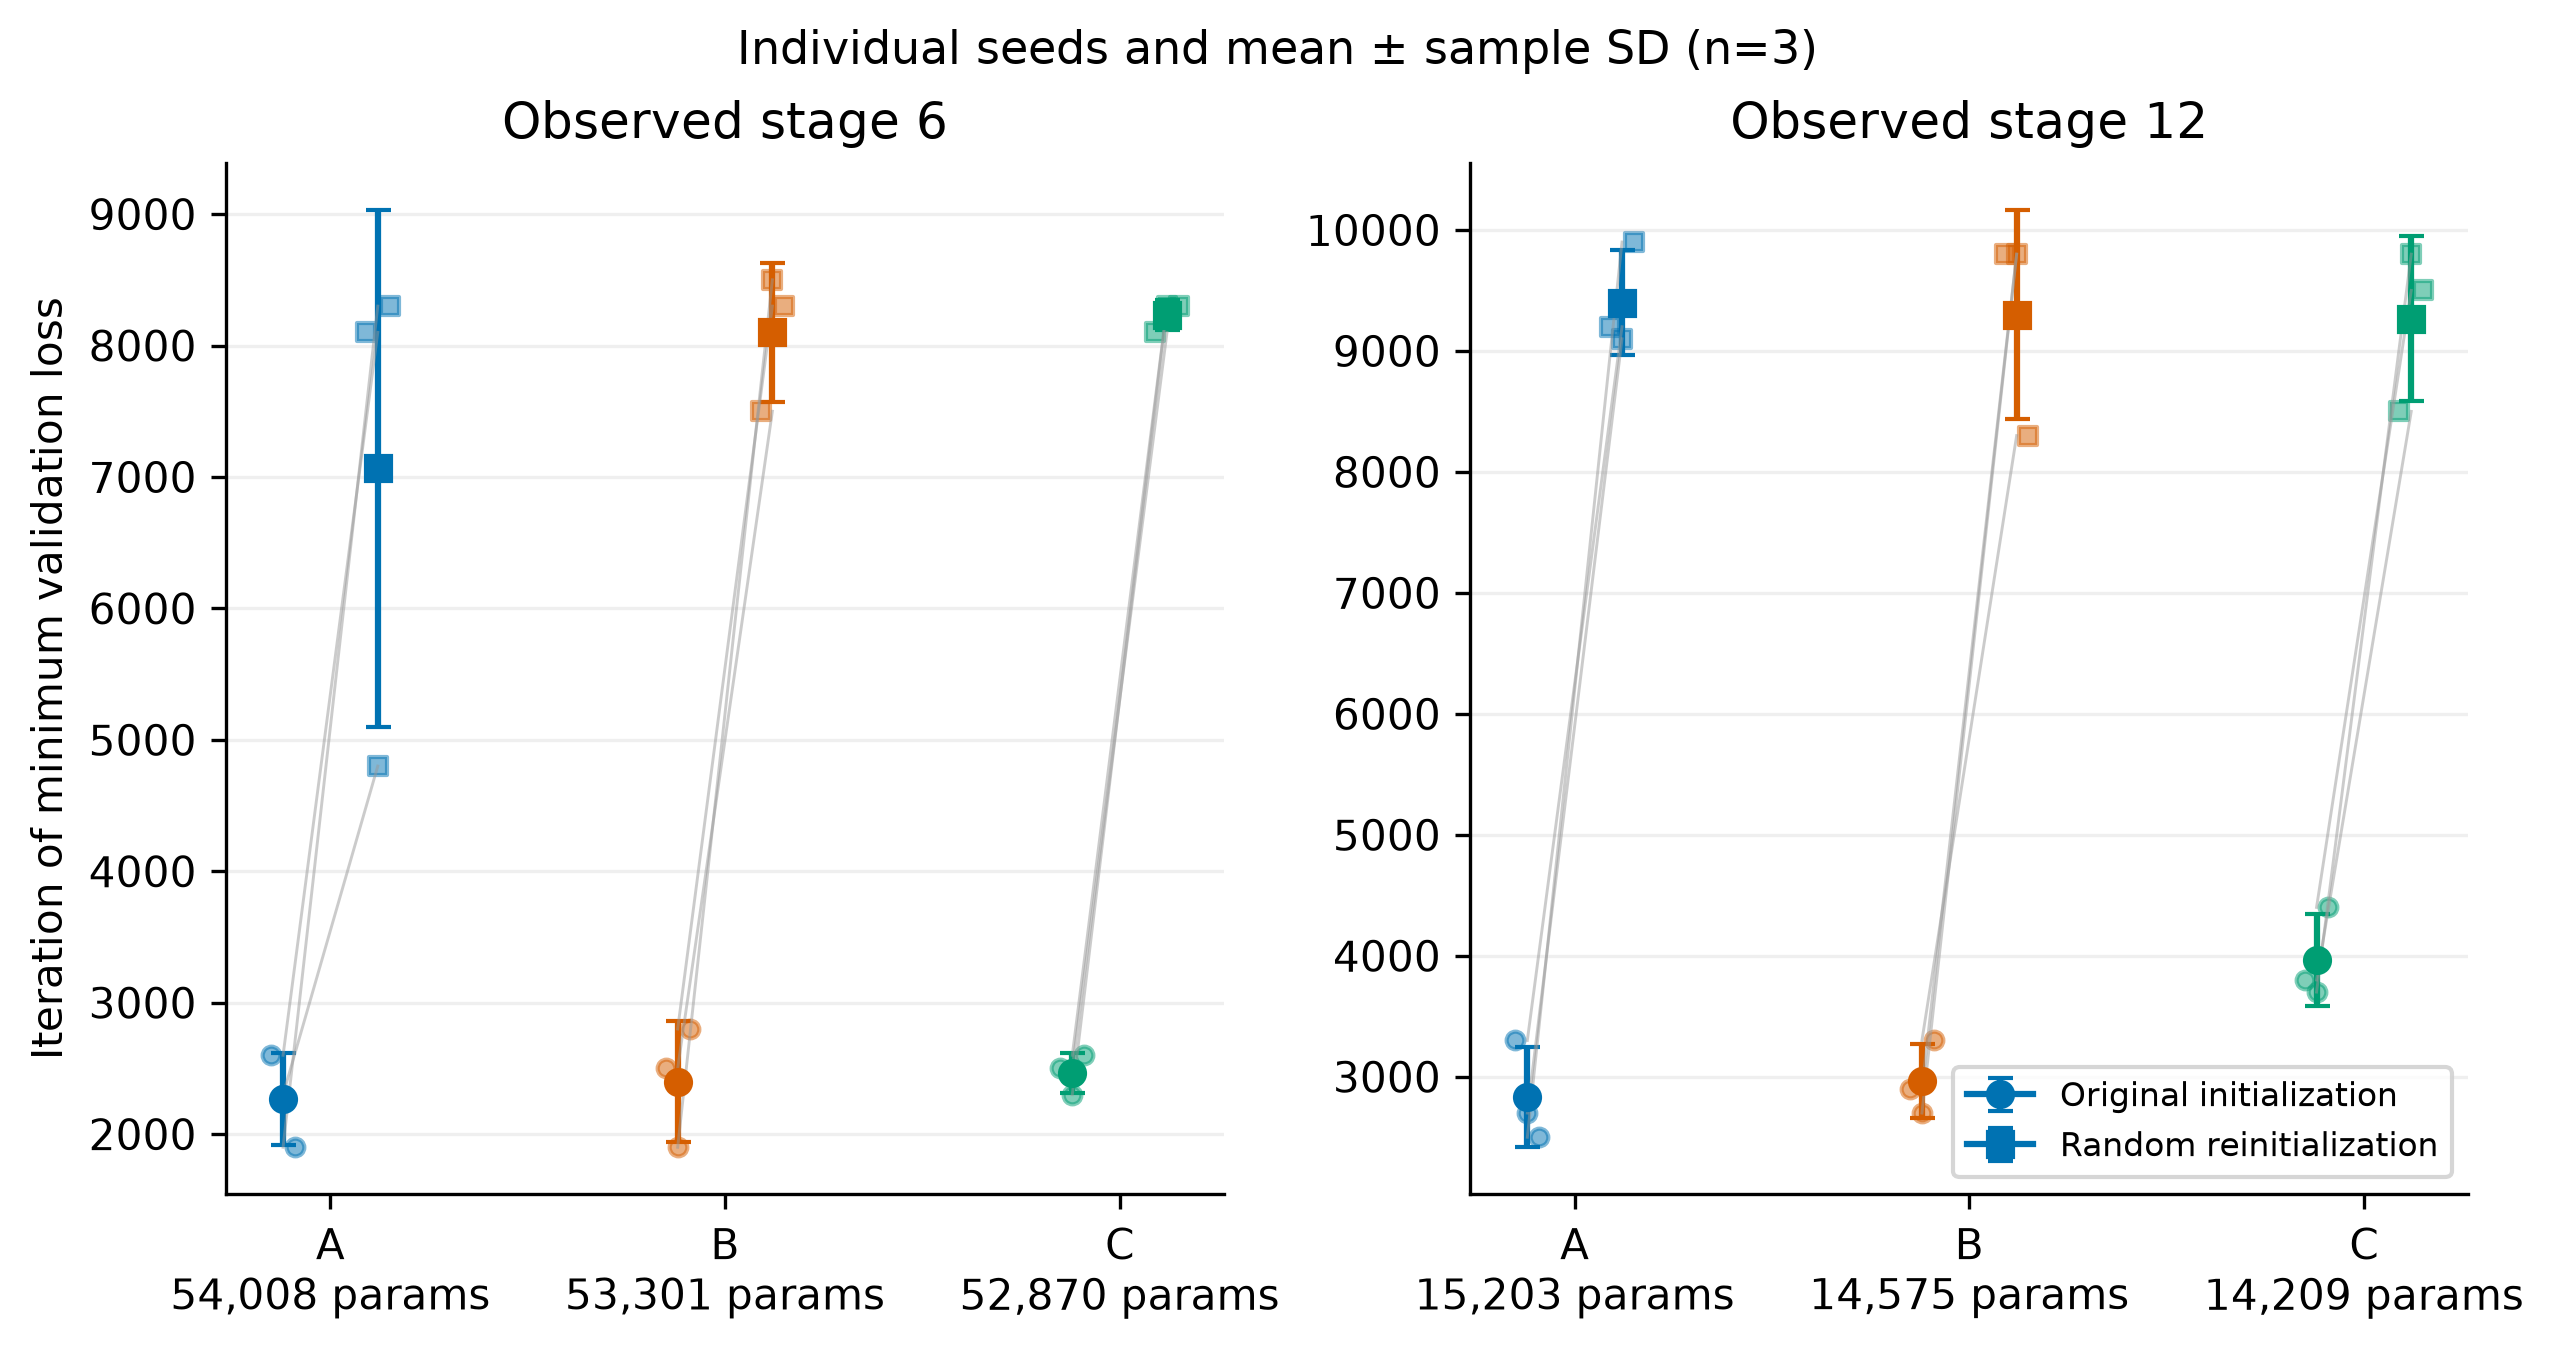

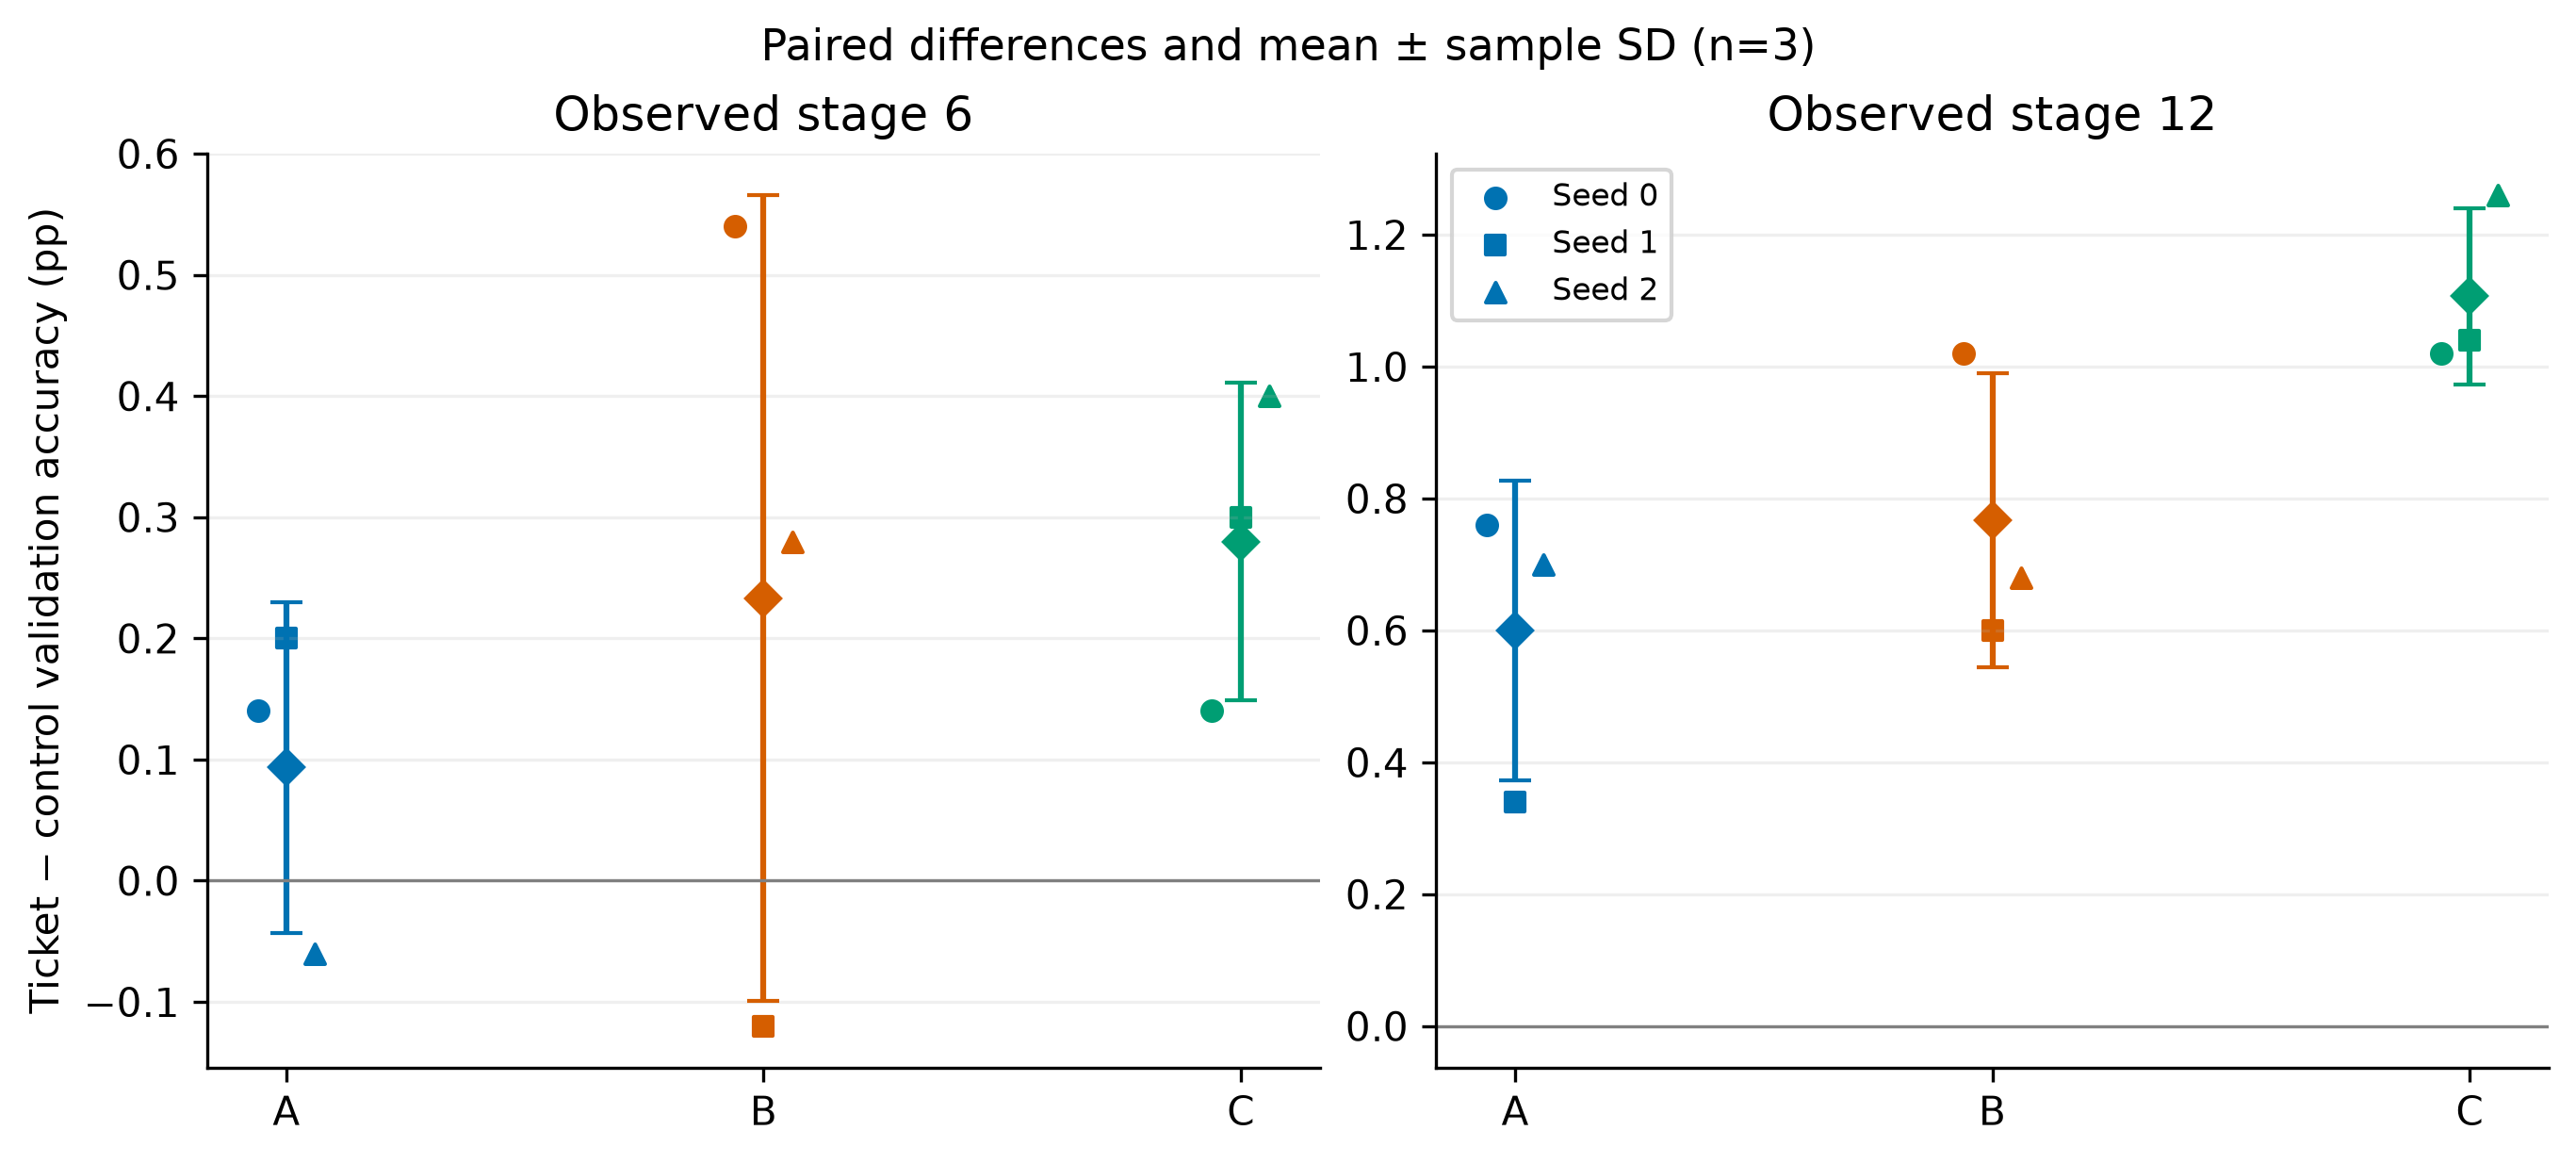

In [4]:
display(results["control_summary"])
for name in ("control_validation_accuracy","control_minimum_loss","control_trainability","paired_validation_initialization_advantage"):
    display(Image(filename=str(DATA_ROOT/"paper_assets"/f"{name}.png")))

## 6. Final held-out test evaluation

Stage 3 originally retained final states, not best-loss weights. Stage 4B recovered **27** selected tickets (stages 0/6/12) only to their previously recorded minimum-loss iterations. Every replay history prefix and endpoint matched validation within absolute loss **1e-8** and accuracy **1e-12**. Maximum endpoint loss discrepancy was **9.02e-17**, with identical accuracy. All 27 tickets and 18 saved controls were verified before evaluating the 10,000-image test set.

Mode A only loads these **45 recorded evaluations**. It performs no model selection, model forward pass on test data, or test-informed hyperparameter change. Mode B saves selected states during training and applies the same validation-before-test selection procedure to its separate reproduction.

The tables retain actual active counts, weight sparsity excluding biases, parameter sparsity including biases, per-seed test accuracy, dense-relative change, and paired initialization differences. Original and random comparisons use the same corresponding original dense baseline. No interpolated 16k/20k test results exist.

,architecture,seed,stage,condition,test_accuracy,test_accuracy_change_pp,remaining_parameters,sparsity,parameter_sparsity
0,A,0,0,original_initialization,0.9780,0.00,200013,0.000000,0.000000
1,A,0,6,original_initialization,0.9818,0.38,54008,0.732148,0.729978
2,A,0,12,original_initialization,0.9823,0.43,15203,0.926738,0.923990
3,A,1,0,original_initialization,0.9795,0.00,200013,0.000000,0.000000
4,A,1,6,original_initialization,0.9820,0.25,54008,0.732148,0.729978
5,A,1,12,original_initialization,0.9808,0.13,15203,0.926738,0.923990
6,A,2,0,original_initialization,0.9802,0.00,200013,0.000000,0.000000
7,A,2,6,original_initialization,0.9813,0.11,54008,0.732148,0.729978
8,A,2,12,original_initialization,0.9812,0.10,15203,0.926738,0.923990
9,B,0,0,original_initialization,0.9788,0.00,200054,0.000000,0.000000


,architecture,stage,condition,test_accuracy_mean,test_accuracy_std,test_accuracy_min,test_accuracy_max,test_loss_mean,test_loss_std,test_loss_min,test_loss_max,test_accuracy_change_pp_mean,test_accuracy_change_pp_std,test_accuracy_change_pp_min,test_accuracy_change_pp_max,validation_accuracy_mean,validation_accuracy_std,validation_accuracy_min,validation_accuracy_max,validation_accuracy_change_pp_mean,validation_accuracy_change_pp_std,validation_accuracy_change_pp_min,validation_accuracy_change_pp_max,selected_iteration_mean,selected_iteration_std,selected_iteration_min,selected_iteration_max,seed_count,remaining_parameters,remaining_weights,sparsity,parameter_sparsity,parameters
0,A,0,original_initialization,0.979233,0.001124,0.9780,0.9802,0.071786,0.002881,0.068658,0.074331,0.000000,0.000000,0.00,0.00,0.979333,0.000808,0.9786,0.9802,0.000000e+00,0.000000,0.00,0.00,4300.000000,1637.070554,2500,5700,3,200013,199420,0.000000,0.000000,200013
1,A,6,original_initialization,0.981700,0.000361,0.9813,0.9820,0.059427,0.001979,0.057238,0.061089,0.246667,0.135031,0.11,0.38,0.980000,0.001114,0.9788,0.9810,6.666667e-02,0.192180,-0.14,0.24,2266.666667,351.188458,1900,2600,3,54008,53415,0.732148,0.729978,200013
2,A,6,random_reinitialization,0.979800,0.001127,0.9785,0.9805,0.067275,0.001670,0.066174,0.069197,0.056667,0.177858,-0.10,0.25,0.979067,0.000757,0.9782,0.9796,-2.666667e-02,0.110151,-0.10,0.10,7066.666667,1965.536398,4800,8300,3,54008,53415,0.732148,0.729978,200013
3,A,12,original_initialization,0.981433,0.000777,0.9808,0.9823,0.059378,0.000903,0.058515,0.060317,0.220000,0.182483,0.10,0.43,0.979333,0.000115,0.9792,0.9794,3.700743e-15,0.091652,-0.10,0.08,2833.333333,416.333200,2500,3300,3,15203,14610,0.926738,0.923990,200013
4,A,12,random_reinitialization,0.975700,0.000693,0.9749,0.9761,0.079234,0.003700,0.076252,0.083375,-0.353333,0.051316,-0.41,-0.31,0.973333,0.002318,0.9718,0.9760,-6.000000e-01,0.249800,-0.80,-0.32,9400.000000,435.889894,9100,9900,3,15203,14610,0.926738,0.923990,200013
5,B,0,original_initialization,0.978500,0.001179,0.9772,0.9795,0.078237,0.008208,0.072949,0.087693,0.000000,0.000000,0.00,0.00,0.977933,0.001102,0.9768,0.9790,0.000000e+00,0.000000,0.00,0.00,5033.333333,3106.981386,2500,8500,3,200054,199640,0.000000,0.000000,200054
6,B,6,original_initialization,0.982267,0.000451,0.9818,0.9827,0.056306,0.000374,0.056003,0.056723,0.376667,0.140475,0.23,0.51,0.981000,0.001114,0.9798,0.9820,3.066667e-01,0.197315,0.08,0.44,2400.000000,458.257569,1900,2800,3,53301,52887,0.735088,0.733567,200054
7,B,6,random_reinitialization,0.979667,0.001680,0.9782,0.9815,0.071455,0.005052,0.067426,0.077123,0.116667,0.076376,0.05,0.20,0.978667,0.002212,0.9766,0.9810,7.333333e-02,0.185831,-0.14,0.20,8100.000000,529.150262,7500,8500,3,53301,52887,0.735088,0.733567,200054
8,B,12,original_initialization,0.982933,0.001405,0.9816,0.9844,0.056805,0.002035,0.054516,0.058408,0.443333,0.202073,0.21,0.56,0.980933,0.000503,0.9804,0.9814,3.000000e-01,0.060000,0.24,0.36,2966.666667,305.505046,2700,3300,3,14575,14161,0.929067,0.927145,200054
9,B,12,random_reinitialization,0.974200,0.001300,0.9729,0.9755,0.084168,0.004223,0.079399,0.087430,-0.430000,0.100000,-0.53,-0.33,0.973267,0.002318,0.9708,0.9754,-4.666667e-01,0.220303,-0.72,-0.32,9300.000000,866.025404,8300,9800,3,14575,14161,0.929067,0.927145,200054


,architecture,stage,ticket_minus_control_test_accuracy_pp_mean,ticket_minus_control_test_accuracy_pp_std,ticket_minus_control_test_accuracy_pp_min,ticket_minus_control_test_accuracy_pp_max,ticket_minus_control_validation_accuracy_pp_mean,ticket_minus_control_validation_accuracy_pp_std,ticket_minus_control_validation_accuracy_pp_min,ticket_minus_control_validation_accuracy_pp_max,ticket_minus_control_test_loss_mean,ticket_minus_control_test_loss_std,ticket_minus_control_test_loss_min,ticket_minus_control_test_loss_max,seed_count,ticket_accuracy_higher_count,control_accuracy_higher_count,accuracy_tied_count
0,A,6,0.190000,0.140000,0.09,0.35,0.093333,0.136137,-0.06,0.20,-0.007848,0.001239,-0.008936,-0.006499,3,3,0,0
1,A,12,0.573333,0.145717,0.47,0.74,0.600000,0.227156,0.34,0.76,-0.019856,0.004559,-0.024859,-0.015935,3,3,0,0
2,B,6,0.260000,0.202237,0.03,0.41,0.233333,0.332466,-0.12,0.54,-0.015149,0.005243,-0.020931,-0.010703,3,3,0,0
3,B,12,0.873333,0.125831,0.74,0.99,0.766667,0.223010,0.60,1.02,-0.027363,0.002188,-0.029022,-0.024882,3,3,0,0
4,C,6,0.393333,0.098658,0.28,0.46,0.280000,0.131149,0.14,0.40,-0.015148,0.004611,-0.020216,-0.011200,3,3,0,0
5,C,12,0.843333,0.293995,0.60,1.17,1.106667,0.133167,1.02,1.26,-0.030673,0.004988,-0.036423,-0.027520,3,3,0,0


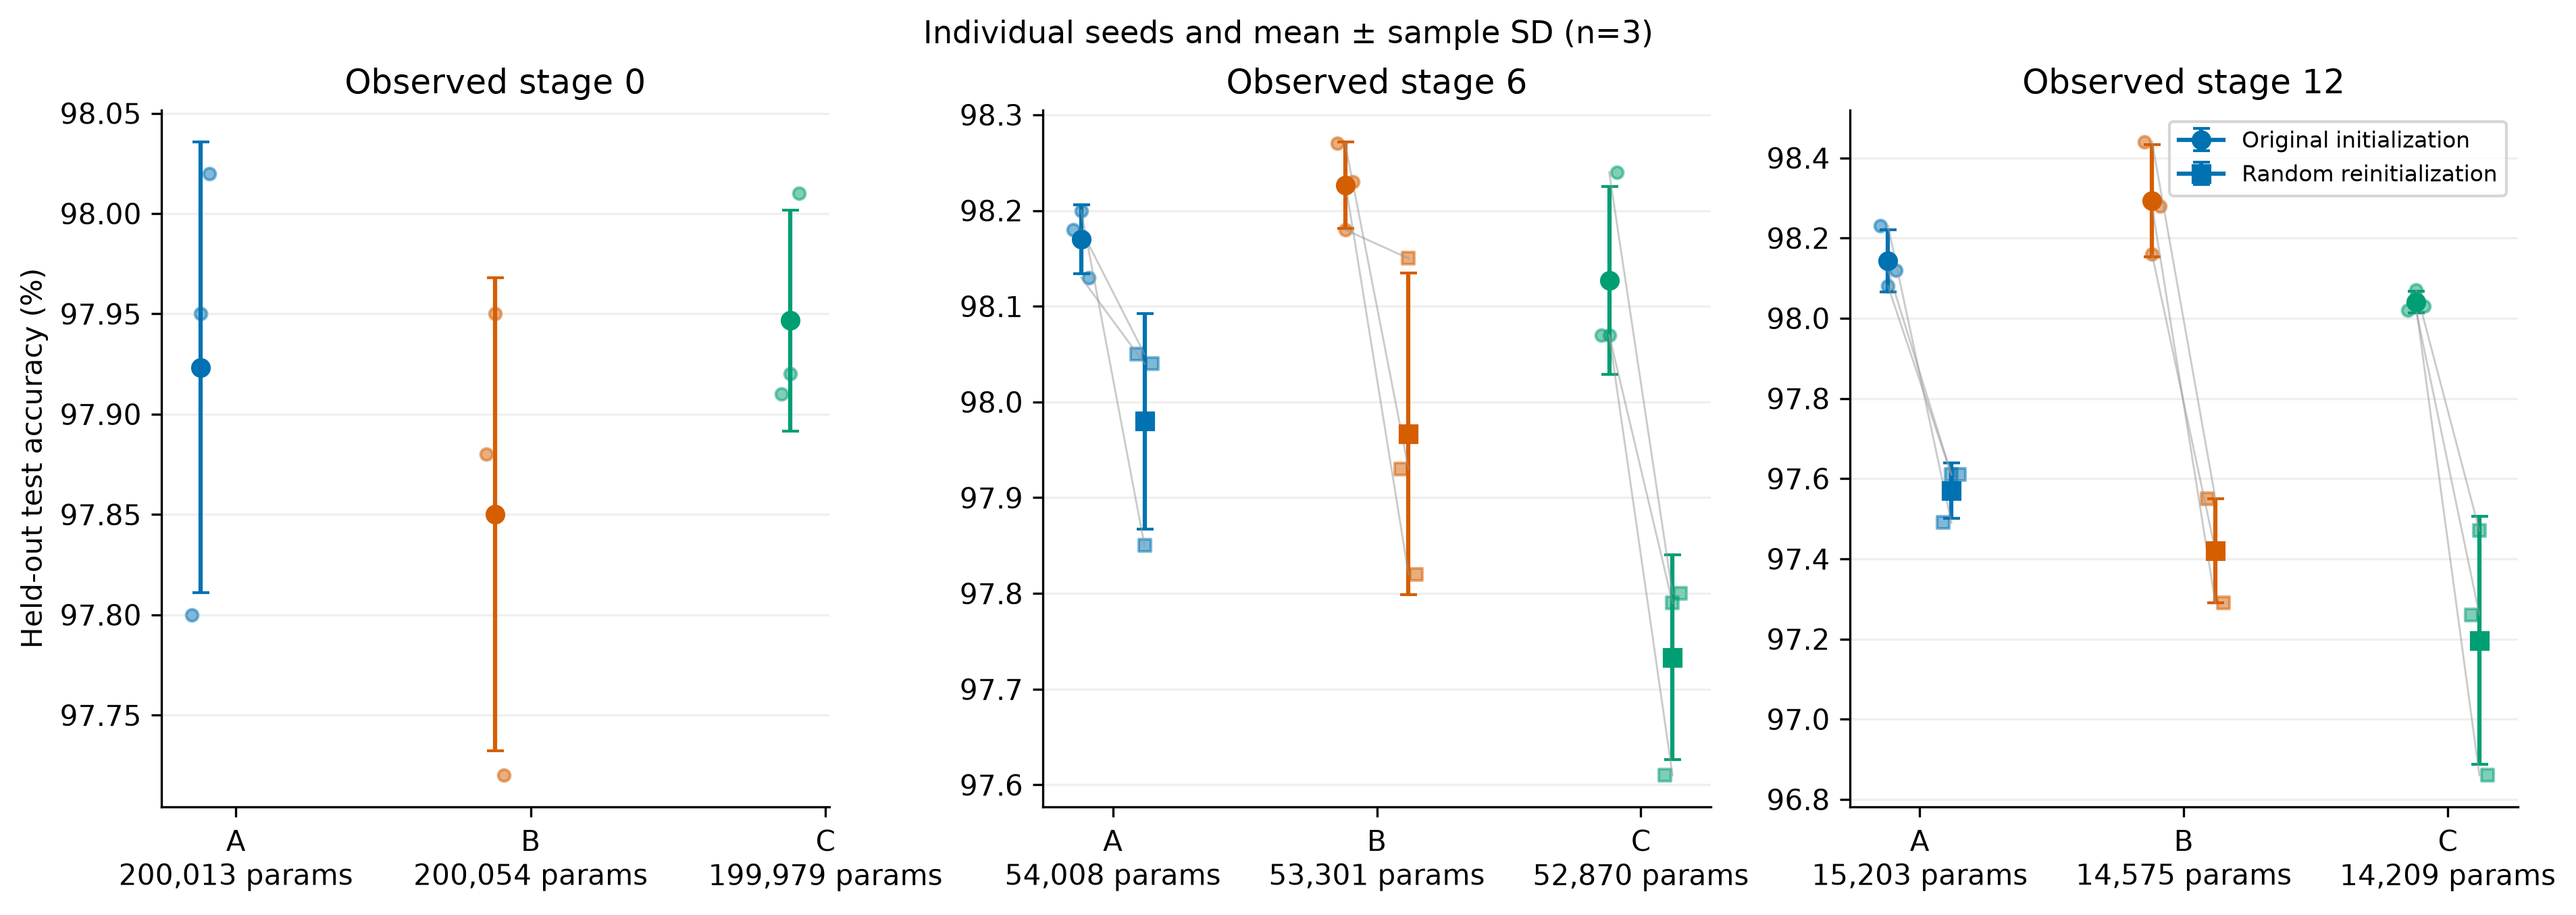

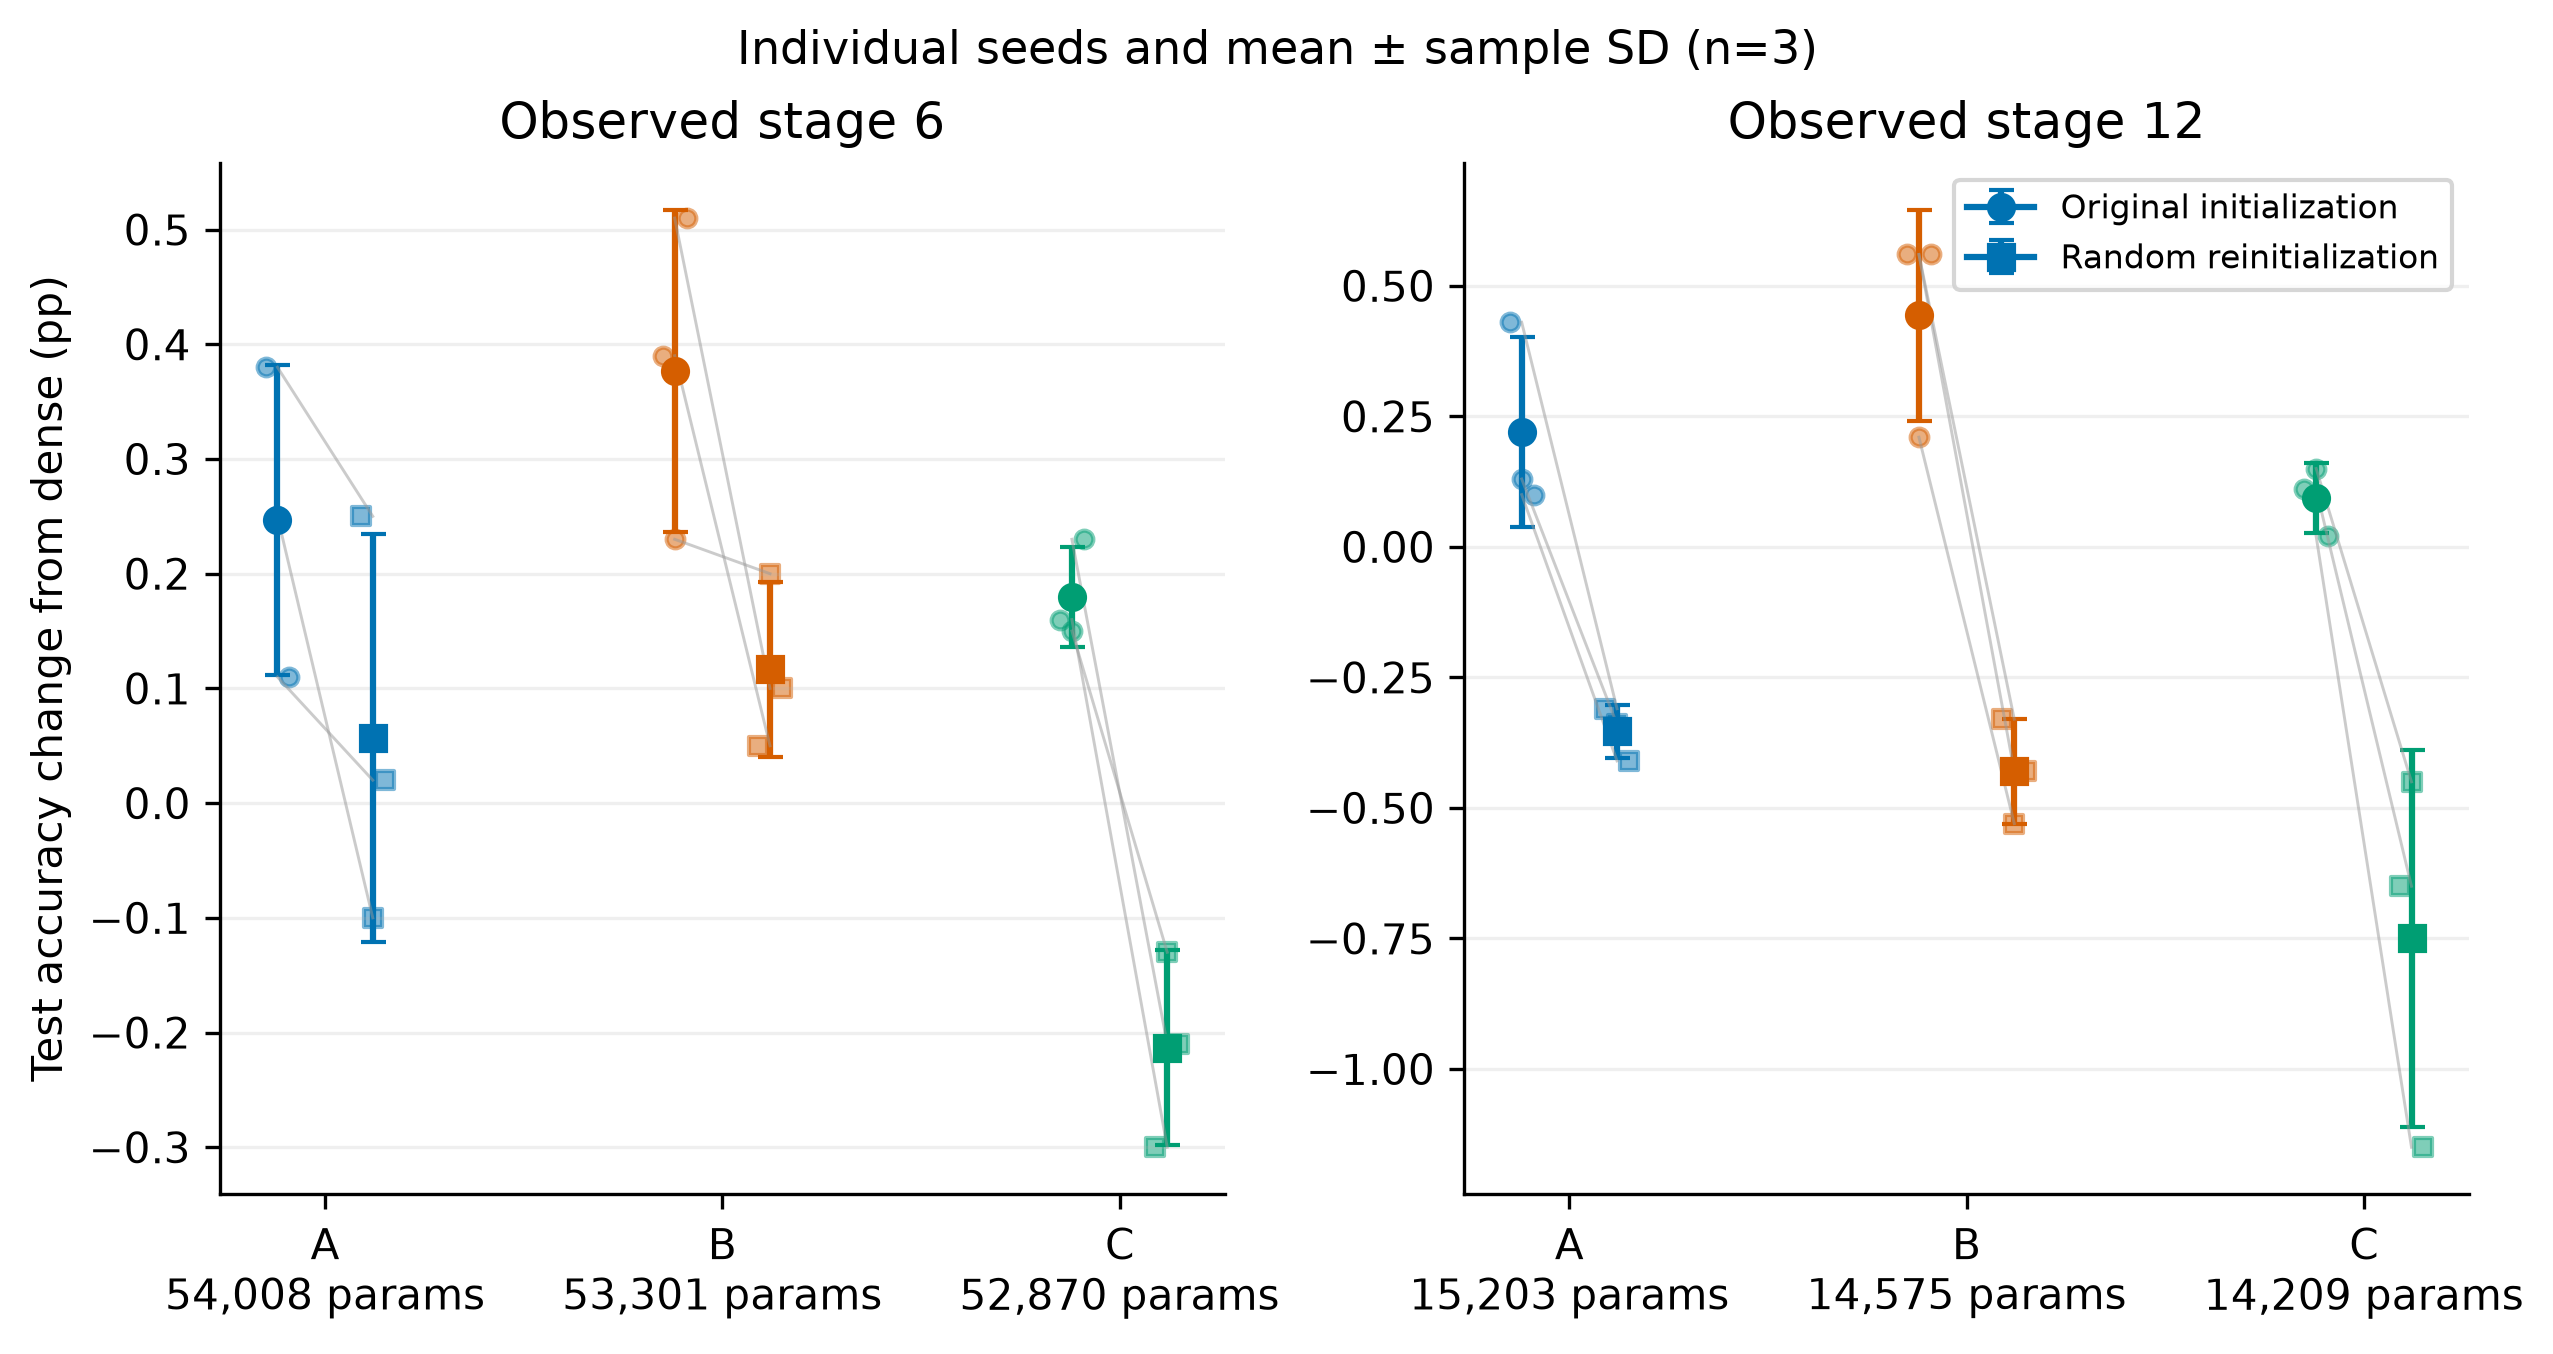

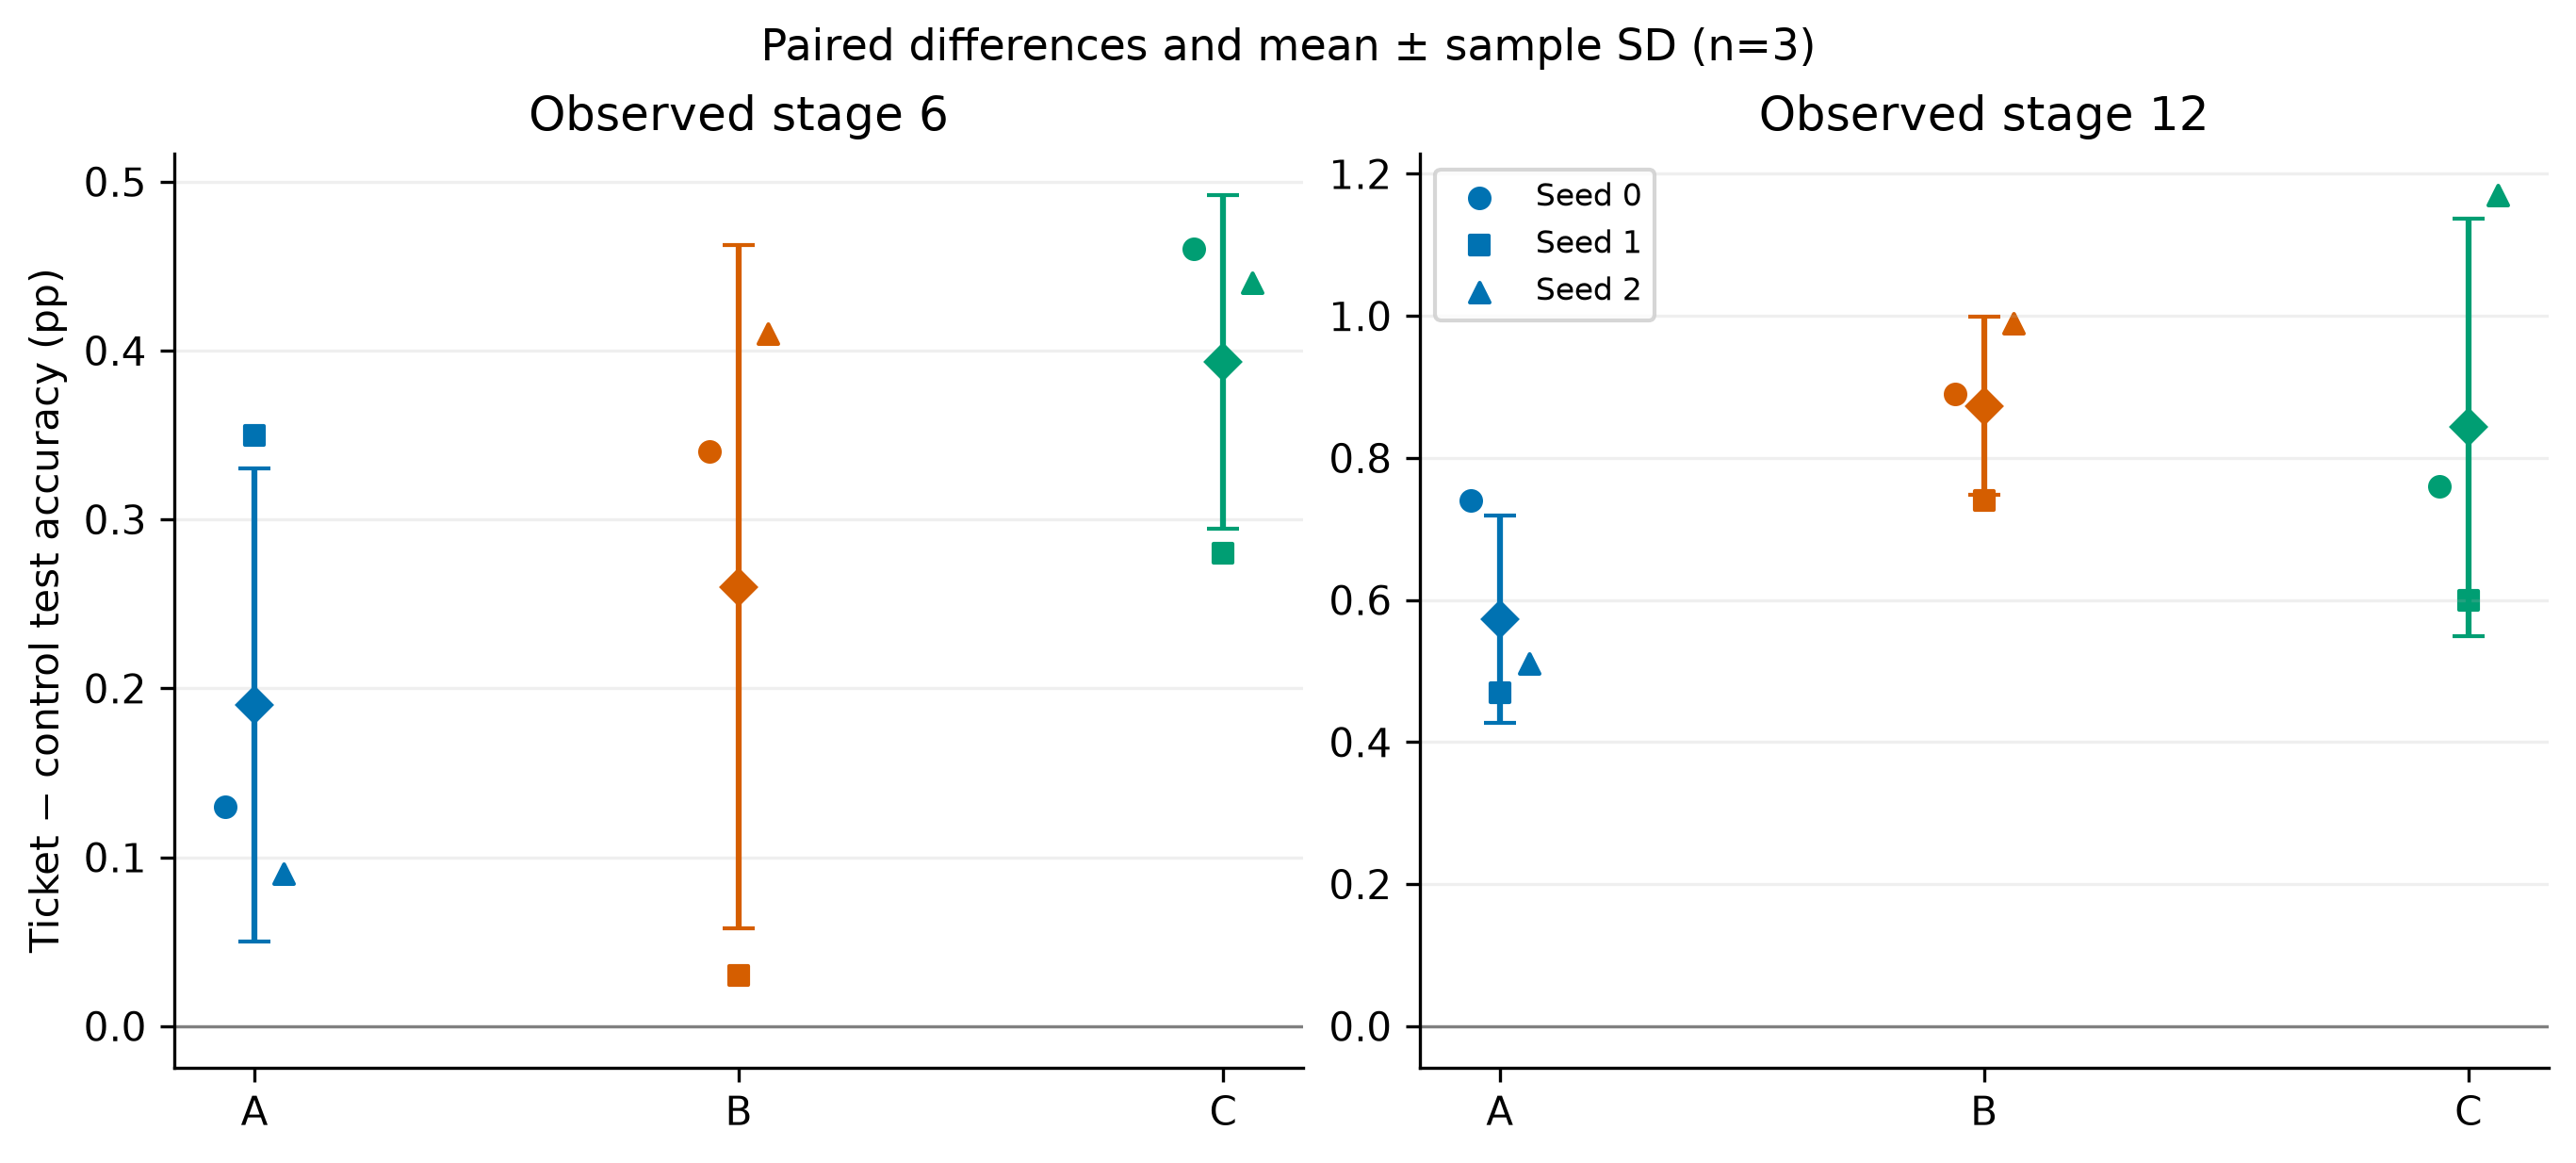

In [5]:
display(results["test"][["architecture","seed","stage","condition","test_accuracy","test_accuracy_change_pp","remaining_parameters","sparsity","parameter_sparsity"]])
display(results["test_summary"])
display(results["test_paired_summary"])
for name in ("held_out_test_accuracy","dense_relative_test_accuracy","paired_test_initialization_advantage"):
    display(Image(filename=str(DATA_ROOT/"paper_assets"/f"{name}.png")))

## 7. Final research findings and limitations

The following statements describe the **original verified study**, not a claim that every optional fresh reproduction will have the same numerical outcome:

- B had the highest mean held-out original-ticket accuracy at stage 12: **98.293 ± 0.140%**.
- B had the largest mean dense-relative stage-12 test improvement: **+0.443 ± 0.202 pp**, leading this metric in all three seeds at that stage.
- Original initialization outperformed same-mask random controls in **18/18 held-out paired comparisons**.
- Ratios exhibited different observed trainability patterns. At high sparsity C selected validation minima later than the other tickets; metric and sparsity matter.
- Initialization sensitivity is not architectural superiority. C had the largest validation initialization advantage, while on test at stage 12 B's mean advantage (**+0.873 ± 0.126 pp**) slightly exceeded C's (**+0.843 ± 0.294 pp**). A had the highest mean random-control accuracy there. Architecture ranking depends on initialization condition and metric.

Only three seeds and one shared split/test set were studied. Dense parameters are approximate, and actual remaining counts/mask geometry differ across ratios. The budget is **10k instead of the paper's 50k updates**. Controls may be budget-limited: **16/18** minima occurred within their final 20% of training. Selected iteration is a retrospective validation-loss measure, not a proof of optimization convergence or asymptotic trainability. No statistically established universally superior ratio follows.

All CSV and LaTeX tables and PDF/PNG figures are in `paper_assets/`. Original artifacts and checkpoint hashes remain unchanged. See `README.md` and `packaging/verification.md` for commands, integrity evidence and verification limits.

In [6]:
# Check every delivered data artifact. No training or test evaluation here.
if MODE=="A":
    print(verify_artifacts(ROOT,check_all=True))
print("Workflow complete. No additional experiment is launched.")

{'selected_checkpoints': 45, 'manifest_files_checked': 1202, 'status': 'verified', 'training_performed': False}
Workflow complete. No additional experiment is launched.
